# Combined EDA

# Part 1: Daniel - EIU Democracy EDA

# EDA: `democracy-eiu.csv` (Daniel)

We split this checkpoint by CSV, and this one is mine: the **EIU Democracy Index** panel, where one row is one country (or region) in one year with a score from 0 to 10. This notebook covers all six steps for this file: the profile, anomalies, distributions, relationships, "so what?", and "what next?".

Our research questions, from the Checkpoint 3 README:

- **RQ1 (primary):** How strongly does a country's level of democracy correlate with its Human Development Index (HDI) and inequality-adjusted HDI (IHDI) across regions, and does inequality play a mediating role?
- **RQ2 (secondary):** Can election dynamics like turnout and electoral system changes act as early indicators of shifts or declines in a country's democracy score?

For the relationship plots I join to `hdi-ihdi-democracy-by-country.csv` (our secondary dataset) on the country code, and I cross-check against `democracy-index-eiu.csv`.

In [1]:
from pathlib import Path

import polars as pl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(160)

DATA = Path("..")          # the CSVs live in the repo root
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)

BLUE = "#2a78d6"
INK = "#0b0b0b"
MUTED = "#52514e"
GRAY = "#9a9893"
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRAY,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
})


def save(fig, name):
    fig.savefig(FIGS / f"daniel_{name}.png", bbox_inches="tight", dpi=150)


eiu = pl.read_csv(DATA / "democracy-eiu.csv")
eiu_index = pl.read_csv(DATA / "democracy-index-eiu.csv")        # Daunovan's file, used for a cross-check
hdi = pl.read_csv(DATA / "hdi-ihdi-democracy-by-country.csv")    # Kam's file, used for the join

## 1. Profile

In [2]:
print("shape:", eiu.shape)
eiu.glimpse()

shape: (2610, 4)
Rows: 2610
Columns: 4
$ Entity        <str> 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan'
$ Code          <str> 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG'
$ Year          <i64> 2006, 2008, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017
$ democracy_eiu <f64> 3.06, 3.02, 2.48, 2.48, 2.48, 2.48, 2.77, 2.77, 2.55, 2.55



In [3]:
eiu.null_count()

Entity,Code,Year,democracy_eiu
u32,u32,u32,u32
0,90,0,0


In [4]:
eiu.describe()

statistic,Entity,Code,Year,democracy_eiu
str,str,str,f64,f64
"""count""","""2610""","""2520""",2610.0,2610.0
"""null_count""","""0""","""90""",0.0,0.0
"""mean""",null,null,2014.8,5.489203
"""std""",null,null,4.651339,2.195893
"""min""","""Afghanistan""","""AFG""",2006.0,0.32
"""25%""",null,null,2011.0,3.53
"""50%""",null,null,2015.0,5.78
"""75%""",null,null,2019.0,7.24
"""max""","""Zimbabwe""","""ZWE""",2022.0,9.93


In [5]:
print("entities:", eiu["Entity"].n_unique(), "| codes:", eiu["Code"].n_unique())
print("rows per entity:", eiu.group_by("Entity").agg(pl.len())["len"].unique().to_list())
print("years:", eiu["Year"].unique().sort().to_list())

entities: 174 | codes: 169
rows per entity: [15]
years: [2006, 2008, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]


**What stands out:**

- **2,610 rows × 4 columns** (`Entity`, `Code`, `Year`, `democracy_eiu`), with 174 entities and exactly 15 rows each, so the panel is perfectly balanced.
- The years are **2006, 2008, and 2010 to 2022**. 2007 and 2009 aren't there, and nothing goes past 2022 even though our Checkpoint 3 README says "2006 through 2023".
- `Code` is missing for 90 rows. Those turn out to be continent rows (Africa, Asia, ...), not countries, so only 167 of the 174 entities are actually countries.
- Scores run from 0.32 to 9.93 on the 0 to 10 scale, so nothing is out of range. The median (5.78) is higher than the mean (5.49), so there's a slightly longer tail at the low end.

## 2. Anomalies

I checked for the six issue types from Week 3 (missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units), plus issues that show up when this file is compared or joined with our other CSVs. The full table is at the end of this section.

### 2a. Region rows mixed in with countries

In [6]:
is_aggregate = pl.col("Code").is_null() | pl.col("Code").str.starts_with("OWID_")
aggregates = eiu.filter(is_aggregate)
print("aggregate rows:", aggregates.height, "| entities:", sorted(aggregates["Entity"].unique().to_list()))
print("rows with no Code:", eiu["Code"].null_count(), "| rows with a non-ISO OWID_ code:", eiu.filter(pl.col("Code").str.starts_with("OWID_")).height)

countries = eiu.filter(~is_aggregate)
for year in [2006, 2022]:
    world_row = eiu.filter((pl.col("Entity") == "World") & (pl.col("Year") == year))["democracy_eiu"].item()
    country_mean = countries.filter(pl.col("Year") == year)["democracy_eiu"].mean()
    print(f"{year}: World row = {world_row:.4f} | plain mean of the 167 countries = {country_mean:.4f}")

aggregate rows: 105 | entities: ['Africa', 'Asia', 'Europe', 'North America', 'Oceania', 'South America', 'World']
rows with no Code: 90 | rows with a non-ISO OWID_ code: 15
2006: World row = 5.5193 | plain mean of the 167 countries = 5.5193
2022: World row = 5.2932 | plain mean of the 167 countries = 5.2932


"World" is just the plain average of the 167 countries, and the continent rows are averages too. Leaving them in would count every country twice. I **removed them from the country table**, but I kept them in their own table for the region plot in step 4.

### 2b. Missing years and the 2023 claim

In [7]:
all_years = list(range(2006, 2023))
missing_years = sorted(set(all_years) - set(eiu["Year"].unique().to_list()))
print("missing years:", missing_years, "->", countries["Entity"].n_unique() * len(missing_years), "country-years absent")
print("last year in democracy-eiu.csv:", eiu["Year"].max())
print("2023 rows in democracy-index-eiu.csv:", eiu_index.filter(pl.col("Year") == 2023).height)

missing years: [2007, 2009] -> 334 country-years absent
last year in democracy-eiu.csv: 2022
2023 rows in democracy-index-eiu.csv: 155


### 2c. Comparing against `democracy-index-eiu.csv`

In [8]:
keys = ["Entity", "Year"]
both = eiu.join(eiu_index.select(*keys, pl.col("Democracy score").alias("index_score")), on=keys, how="left")
print("rows of democracy-eiu.csv found in democracy-index-eiu.csv:", both.filter(pl.col("index_score").is_not_null()).height, "of", eiu.height)
gap = (both["democracy_eiu"] - both["index_score"]).abs()
print("rows that differ by more than 0.001:", both.filter((pl.col("democracy_eiu") - pl.col("index_score")).abs() > 0.001).height)
print(f"largest difference anywhere: {gap.max():.1e} (float rounding)")
print("columns in democracy-index-eiu.csv:", eiu_index.columns)

rows of democracy-eiu.csv found in democracy-index-eiu.csv: 2610 of 2610
rows that differ by more than 0.001: 0
largest difference anywhere: 6.7e-07 (float rounding)
columns in democracy-index-eiu.csv: ['Entity', 'Code', 'Year', 'Democracy score']


Every one of my 2,610 rows shows up in `democracy-index-eiu.csv` with **the same score**. The largest difference anywhere is under 0.000001, which is just float rounding. So the two files are the same EIU data, and the other one just adds 2023 for 155 countries. Neither file has the sub-scores (civil liberties, political participation, and so on) that our Checkpoint 3 README says the second file provides. **The group should know this before treating them as two separate datasets.**

### 2d. Formatting, repeated values, and clean checks

In [9]:
extra_decimals = (pl.col("democracy_eiu") * 100 - (pl.col("democracy_eiu") * 100).round(0)).abs() > 1e-9
print("values with more than 2 decimals:", eiu.filter(extra_decimals).height, "| in country rows:", eiu.filter(extra_decimals & ~is_aggregate).height)

changes = (
    countries.sort("Entity", "Year")
    .with_columns(
        pl.col("democracy_eiu").diff().over("Entity").alias("change"),
        pl.col("Year").diff().over("Entity").alias("years_apart"),
    )
)
annual = changes.filter(pl.col("years_apart") == 1)
print(f"one-year changes: {annual.height} | exactly 0: {annual.filter(pl.col('change') == 0).height} ({annual.filter(pl.col('change') == 0).height / annual.height:.1%})")

print("\n-- clean checks --")
print("exact duplicate rows:", eiu.is_duplicated().sum(), "| duplicate (Entity, Year):", eiu.select(pl.struct(keys).is_duplicated().sum()).item())
print("scores outside 0-10:", eiu.filter(~pl.col("democracy_eiu").is_between(0, 10)).height)
print("names with extra spaces:", eiu.filter(pl.col("Entity") != pl.col("Entity").str.strip_chars()).height)
print("country codes that aren't 3 letters:", countries.filter(pl.col("Code").str.len_chars() != 3).height)

values with more than 2 decimals: 99 | in country rows: 0
one-year changes: 2004 | exactly 0: 679 (33.9%)

-- clean checks --
exact duplicate rows: 0 | duplicate (Entity, Year): 0
scores outside 0-10: 0
names with extra spaces: 0
country codes that aren't 3 letters: 0


### 2e. Problems that show up when joining to the HDI file

In [10]:
print("HDI file:", hdi.shape, "| years:", hdi["Year"].unique().to_list())
print("IHDI dtype:", hdi.schema["IHDI"], "| non-numeric IHDI values:",
      hdi.filter(pl.col("IHDI").cast(pl.Float64, strict=False).is_null())["IHDI"].value_counts(sort=True).rows())

hdi_clean = hdi.select(
    pl.col("country_code").alias("Code"),
    pl.col("Country").alias("hdi_name"),
    "HDI",
    pl.col("IHDI").cast(pl.Float64, strict=False),
)
eiu_2022 = countries.filter(pl.col("Year") == 2022)
joined = eiu_2022.join(hdi_clean, on="Code", how="left")

no_ihdi = joined.filter(pl.col("HDI").is_not_null() & pl.col("IHDI").is_null())
print("\nEIU countries with no HDI:", joined.filter(pl.col("HDI").is_null())["Entity"].to_list())
print("EIU countries with HDI but no IHDI:", no_ihdi["Entity"].to_list())
print("  of those, authoritarian (score <= 4):", no_ihdi.filter(pl.col("democracy_eiu") <= 4).height,
      "| above 6:", no_ihdi.filter(pl.col("democracy_eiu") > 6).select("Entity", "democracy_eiu").rows())
print("same code, different name:", joined.filter(pl.col("hdi_name").is_not_null() & (pl.col("hdi_name") != pl.col("Entity"))).select("Entity", "hdi_name").rows())
print("HDI countries with no EIU score:", hdi_clean.join(eiu_2022, on="Code", how="anti").height)

HDI file: (194, 8) | years: [2023]
IHDI dtype: String | non-numeric IHDI values: [('..', 28), (None, 1)]

EIU countries with no HDI: ['North Korea', 'Taiwan']
EIU countries with HDI but no IHDI: ['Bahrain', 'Cuba', 'Equatorial Guinea', 'Eritrea', 'Guyana', 'Kuwait', 'Lebanon', 'Libya', 'Qatar', 'Saudi Arabia', 'Suriname', 'Syria', 'Trinidad and Tobago', 'Turkmenistan', 'Uzbekistan']
  of those, authoritarian (score <= 4): 12 | above 6: [('Guyana', 6.34), ('Suriname', 6.95), ('Trinidad and Tobago', 7.16)]
same code, different name: [('Democratic Republic of Congo', 'Congo (Democratic Republic of the)'), ('Iran', 'Iran (Islamic Republic of)'), ('Laos', "Lao People's Democratic Republic"), ('Syria', 'Syrian Arab Republic')]
HDI countries with no EIU score: 28


- **IHDI is stored as text** because missing values are written as `".."`. I cast it to a float, so those become nulls.
- **The IHDI gaps aren't random.** 12 of the 15 EIU countries that lose their IHDI are authoritarian (score 4 or below), including Bahrain, Qatar, Saudi Arabia, Kuwait, Cuba, and Syria. The other 3 are Guyana, Suriname, and Trinidad and Tobago. Those are some of the richest non-democracies, so any plot that uses IHDI leaves out exactly the countries that break the "democracy goes with development" pattern.
- **Names don't match** for Iran, Laos, Syria, and DR Congo, so I join on `Code`, not on the name.
- **The years don't match.** HDI is 2023 only and my file ends in 2022, so the join pairs EIU 2022 with HDI 2023. EIU scores barely move in one year (see 3.3), so I'm okay with that, but it's flagged.
- **Mixed scales.** EIU runs 0 to 10, while HDI and IHDI run 0 to 1. The HDI file also has its own copy of the EIU score, plus a 0 to 1 version of it. I keep the original 0 to 10 scale and never plot two scales on one axis.

### 2f. Cleaned table and anomaly summary

In [11]:
CATEGORIES = ["Authoritarian", "Hybrid regime", "Flawed democracy", "Full democracy"]
category = pl.Enum(CATEGORIES)
# EIU's own cut points: <= 4 authoritarian, 4-6 hybrid, 6-8 flawed, > 8 full
countries = countries.with_columns(
    pl.when(pl.col("democracy_eiu") > 8).then(pl.lit("Full democracy"))
    .when(pl.col("democracy_eiu") > 6).then(pl.lit("Flawed democracy"))
    .when(pl.col("democracy_eiu") > 4).then(pl.lit("Hybrid regime"))
    .otherwise(pl.lit("Authoritarian"))
    .cast(category)
    .alias("category")
)
regions = aggregates.select("Entity", "Year", "democracy_eiu")
print("countries:", countries.shape, "| region rows kept aside:", regions.shape)

anomalies = pl.DataFrame(
    [
        ("World and continent averages mixed in with countries", "Mixed granularity", f"{aggregates.height}", "Removed from the country table; kept separately for the region plot"),
        ("No Code for the 6 continent rows", "Missing values", f"{eiu['Code'].null_count()}", "Resolved by removing the averages"),
        ("World uses the non-ISO code OWID_WRL", "Inconsistent formatting", f"{eiu.filter(pl.col('Code').str.starts_with('OWID_')).height}", "Resolved by removing the averages"),
        ("No 2007 or 2009 (EIU wasn't annual before 2010)", "Missing years", f"{countries['Entity'].n_unique() * len(missing_years)} country-years", "Left; year-to-year changes only use back-to-back years"),
        ("Checkpoint 3 says 2006-2023, but the file ends at 2022", "Documentation mismatch", "whole file", "Use 2022 as the latest year; 2023 is only in democracy-index-eiu.csv"),
        ("Extra decimals in the region averages", "Inconsistent formatting", f"{eiu.filter(extra_decimals).height}", "Resolved by removing the averages"),
        ("Same data as democracy-index-eiu.csv (that file just adds 2023)", "Duplicate dataset", f"{eiu.height} (every row)", "Flagged for the group; only one file should be used"),
        ("Score unchanged from one year to the next", "Looked stale, isn't", f"{annual.filter(pl.col('change') == 0).height} of {annual.height} changes", "Left; EIU only changes a score when something happens"),
        ("IHDI stored as text, with '..' for missing", "Wrong data type", f"{hdi.filter(pl.col('IHDI').cast(pl.Float64, strict=False).is_null()).height} HDI rows", "Fixed: cast to float, '..' becomes null"),
        ("EIU countries that lose IHDI in the join (12 of 15 authoritarian)", "Missing values (not random)", f"{joined.filter(pl.col('HDI').is_not_null() & pl.col('IHDI').is_null()).height} countries", "Left and flagged; IHDI plots skew democratic"),
        ("EIU countries with no HDI (North Korea, Taiwan)", "Missing values", f"{joined.filter(pl.col('HDI').is_null()).height} countries", "Dropped from HDI plots"),
        ("Country names differ between files (Iran, Laos, Syria, DR Congo)", "Inconsistent formatting", "4 countries", "Joined on Code instead of name"),
        ("EIU on 0-10, HDI and IHDI on 0-1", "Mixed units", "both files", "Kept each scale; never on one axis"),
        ("EIU 2022 joined to HDI 2023", "Time mismatch", f"{joined.filter(pl.col('HDI').is_not_null()).height} joined countries", "Left and flagged"),
    ],
    schema=["anomaly", "type", "rows affected", "what I did"],
    orient="row",
)
with pl.Config(fmt_str_lengths=90, tbl_width_chars=250, tbl_rows=20):
    print(anomalies)

countries: (2505, 5) | region rows kept aside: (105, 3)
shape: (14, 4)
┌───────────────────────────────────────────────────────────────────┬─────────────────────────────┬──────────────────────┬──────────────────────────────────────────────────────────────────────┐
│ anomaly                                                           ┆ type                        ┆ rows affected        ┆ what I did                                                           │
│ ---                                                               ┆ ---                         ┆ ---                  ┆ ---                                                                  │
│ str                                                               ┆ str                         ┆ str                  ┆ str                                                                  │
╞═══════════════════════════════════════════════════════════════════╪═════════════════════════════╪══════════════════════╪═══════════════════════════════

No duplicate rows or keys, no scores outside 0 to 10, and no stray spaces. The biggest issues for the group are that **our two EIU files are the same data**, and that **IHDI is missing for the rich autocracies**.

## 3. Distributions

The main feature is `democracy_eiu`. I look at it in the latest year (2022, 167 countries), as EIU's four categories, and as year-to-year changes. `Year` itself is balanced (167 countries in every one of the 15 years), so it doesn't need its own plot.

In [12]:
def summarize(s, label):
    print(f"{label}: n={s.len()}  mean={s.mean():.3f}  median={s.median():.3f}  sd={s.std():.3f}  "
          f"IQR={s.quantile(0.25):.3f} to {s.quantile(0.75):.3f}  min={s.min():.3f}  max={s.max():.3f}  skew={s.skew():.2f}")


latest = countries.filter(pl.col("Year") == 2022)

### 3.1 Democracy score, 2022

score 2022: n=167  mean=5.293  median=5.540  sd=2.376  IQR=3.120 to 7.130  min=0.320  max=9.810  skew=-0.04
lowest: [('Afghanistan', 0.32), ('Myanmar', 0.74), ('North Korea', 1.08)]
highest: [('Norway', 9.81), ('New Zealand', 9.61), ('Iceland', 9.52)]
countries per 1-point bin: [(0.0, 2), (1.0, 13), (2.0, 23), (3.0, 21), (4.0, 11), (5.0, 25), (6.0, 25), (7.0, 23), (8.0, 15), (9.0, 9)]


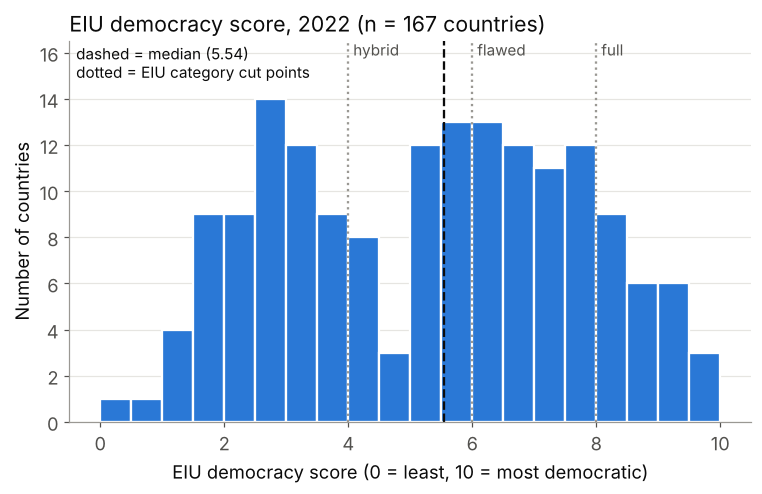

In [13]:
summarize(latest["democracy_eiu"], "score 2022")
print("lowest:", latest.sort("democracy_eiu").select("Entity", "democracy_eiu").head(3).rows())
print("highest:", latest.sort("democracy_eiu", descending=True).select("Entity", "democracy_eiu").head(3).rows())
print("countries per 1-point bin:", latest.with_columns(pl.col("democracy_eiu").floor().clip(0, 9).alias("bin")).group_by("bin").agg(pl.len()).sort("bin").rows())

fig, ax = plt.subplots()
ax.hist(latest["democracy_eiu"].to_list(), bins=[i / 2 for i in range(21)], color=BLUE, edgecolor="white", linewidth=1.5)
for cut, label in [(4, "hybrid"), (6, "flawed"), (8, "full")]:
    ax.axvline(cut, color=GRAY, linestyle=":", linewidth=1.5)
    ax.text(cut + 0.08, 1, label, transform=ax.get_xaxis_transform(), va="top", color=MUTED, fontsize=10)
ax.axvline(latest["democracy_eiu"].median(), color=INK, linestyle="--", linewidth=1.5)
ax.text(0.01, 0.99, f"dashed = median ({latest['democracy_eiu'].median():.2f})\ndotted = EIU category cut points",
        transform=ax.transAxes, va="top", ha="left", fontsize=10, color=INK)
ax.margins(y=0.18)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x", visible=False)
ax.set_xlabel("EIU democracy score (0 = least, 10 = most democratic)")
ax.set_ylabel("Number of countries")
ax.set_title(f"EIU democracy score, 2022 (n = {latest.height} countries)", loc="left")
save(fig, "d1_score_2022")
plt.show()

**Shape:** a very wide spread (SD 2.38, IQR 3.12 to 7.13) across almost the whole 0 to 10 range. The center is median 5.54, mean 5.29, and the skew is about 0 (-0.04). It isn't one bell, though. There's a cluster of authoritarian scores from 2 to 4 (44 countries), a thin middle from 4 to 5 (11 countries), and a bigger cluster from 5 to 8 (73 countries). Afghanistan (0.32), Myanmar (0.74), and North Korea (1.08) are at the bottom, and Norway (9.81) is at the top. No point is an outlier by the 1.5 × IQR rule.

**Why it matters:** with two clusters and a gap in between, "the average country" isn't meaningful. Comparing groups (categories or regions) will be more honest for RQ1 than averages.

### 3.2 EIU category, 2022

shape: (4, 2)
┌──────────────────┬───────────┐
│ category         ┆ countries │
│ ---              ┆ ---       │
│ enum             ┆ u32       │
╞══════════════════╪═══════════╡
│ Authoritarian    ┆ 59        │
│ Hybrid regime    ┆ 36        │
│ Flawed democracy ┆ 48        │
│ Full democracy   ┆ 24        │
└──────────────────┴───────────┘


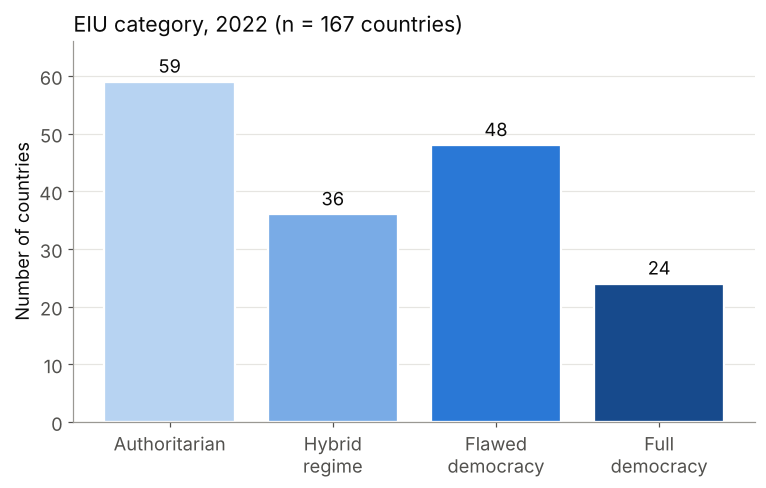

In [14]:
category_counts = latest.group_by("category").agg(pl.len().alias("countries")).sort("category")
print(category_counts)

fig, ax = plt.subplots()
shades = ["#b7d3f2", "#79abe6", "#2a78d6", "#174a8c"]  # one hue, light to dark, because the categories are ordered
labels = [c.replace(" ", "\n", 1) for c in category_counts["category"].cast(pl.String).to_list()]
bars = ax.bar(labels, category_counts["countries"].to_list(), color=shades, edgecolor="white", linewidth=1.5)
ax.bar_label(bars, padding=3, color=INK, fontsize=12)
ax.margins(y=0.12)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Number of countries")
ax.set_title(f"EIU category, 2022 (n = {latest.height} countries)", loc="left")
save(fig, "d2_category_2022")
plt.show()

**Shape:** this is an ordered category, so it gets a bar chart. **Authoritarian is the most common category (59)**, followed by flawed democracy (48), hybrid regime (36), and full democracy (24). Only about 14% of countries are full democracies, and 95 of 167 (57%) fall below the "flawed democracy" line. These counts match the totals EIU itself reported for 2022, which is a good sign the file is complete.

**Why it matters:** for RQ1, the categories give us four groups to compare HDI across (I do that in 4.2), and the groups are big enough to do it (full democracies are the smallest with 24, or 23 after the HDI join).

### 3.3 Year-to-year change in score

one-year change: n=2004  mean=-0.014  median=0.000  sd=0.238  IQR=-0.070 to 0.050  min=-2.530  max=2.740  skew=0.35
exactly 0: 679 | bigger than 1 point either way: 16
biggest drops: [('Afghanistan', 2021, -2.53), ('Myanmar', 2021, -2.02), ('Libya', 2015, -1.55), ('Egypt', 2013, -1.29)]
biggest gains: [('Tunisia', 2011, 2.74), ('Fiji', 2014, 2.0), ('Thailand', 2019, 1.69), ('Libya', 2011, 1.61)]


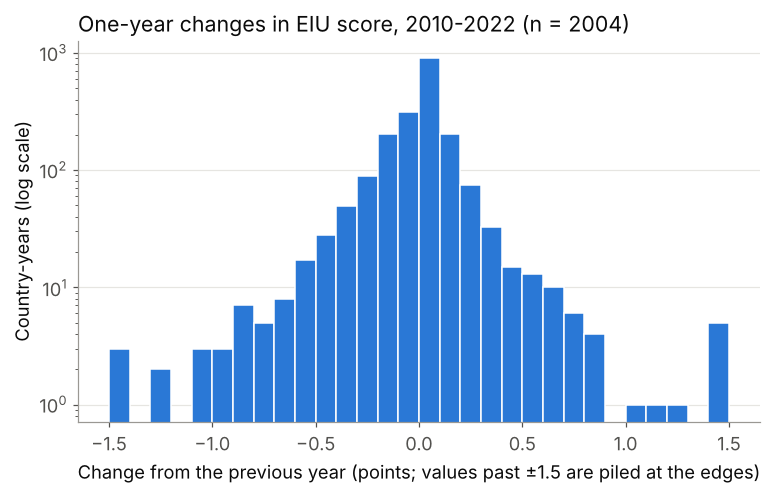

In [15]:
summarize(annual["change"], "one-year change")
print("exactly 0:", annual.filter(pl.col("change") == 0).height, "| bigger than 1 point either way:", annual.filter(pl.col("change").abs() > 1).height)
print("biggest drops:", annual.sort("change").select("Entity", "Year", pl.col("change").round(2)).head(4).rows())
print("biggest gains:", annual.sort("change", descending=True).select("Entity", "Year", pl.col("change").round(2)).head(4).rows())

fig, ax = plt.subplots()
clipped = annual["change"].clip(-1.5, 1.5)
ax.hist(clipped.to_list(), bins=[-1.5 + i * 0.1 for i in range(31)], color=BLUE, edgecolor="white", linewidth=1)
ax.set_yscale("log")
ax.set_xlabel("Change from the previous year (points; values past ±1.5 are piled at the edges)")
ax.set_ylabel("Country-years (log scale)")
ax.grid(axis="x", visible=False)
ax.set_title(f"One-year changes in EIU score, 2010-2022 (n = {annual.height})", loc="left")
save(fig, "d3_annual_change")
plt.show()

**Shape:** a huge spike at 0, since 33.9% of one-year changes are exactly zero. Around it the distribution is narrow (IQR -0.07 to 0.05, median 0) with **long tails**, so I used a log scale to make the rare big moves visible. Only 16 of 2,004 changes are bigger than 1 point. The biggest are Afghanistan's 2021 drop (-2.53), Myanmar's 2021 drop (-2.02), and Tunisia's 2011 jump (+2.74), which are a takeover, a coup, and a revolution. The mean is slightly negative (-0.014), so scores drift down a little over time.

**Why it matters:** most of the "action" for RQ2 is in a small number of big jumps that line up with real events. A model that predicts change will mostly be predicting zero, so we should probably focus on the big moves.

## 4. Relationships

Four plots. 4.1 uses the region rows from this file, and 4.2 and 4.3 use the join with the HDI file.

### 4.1 Democracy over time by continent

World: [(2006, 5.52), (2008, 5.55), (2010, 5.46), (2011, 5.49), (2012, 5.52), (2013, 5.53), (2014, 5.55), (2015, 5.55), (2016, 5.52), (2017, 5.48), (2018, 5.48), (2019, 5.44), (2020, 5.37), (2021, 5.28), (2022, 5.29)]
Europe: 7.75 (2006) -> 7.40 (2022), change -0.35
Oceania: 7.58 (2006) -> 7.46 (2022), change -0.12
South America: 6.52 (2006) -> 6.25 (2022), change -0.27
North America: 6.57 (2006) -> 5.76 (2022), change -0.80
Asia: 4.38 (2006) -> 4.23 (2022), change -0.15
Africa: 4.11 (2006) -> 4.07 (2022), change -0.03


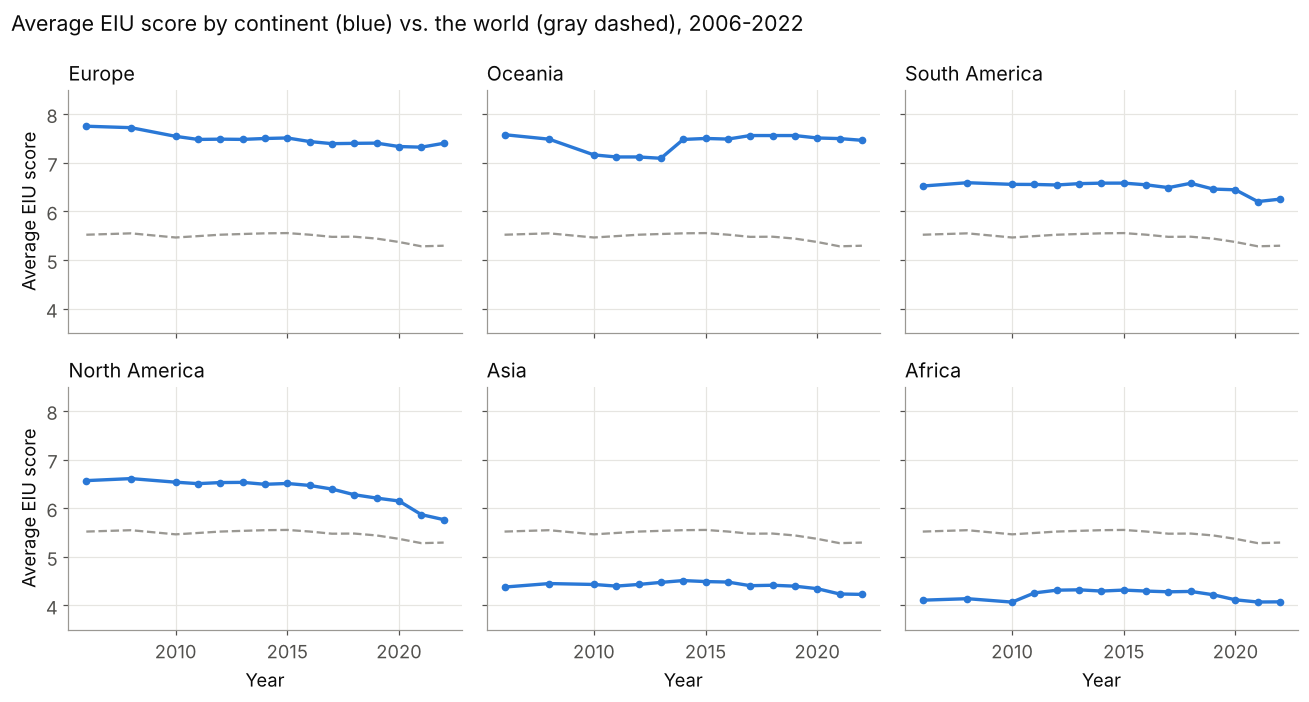

In [16]:
CONTINENTS = ["Europe", "Oceania", "South America", "North America", "Asia", "Africa"]
world = regions.filter(pl.col("Entity") == "World").sort("Year")
print("World:", world.select("Year", pl.col("democracy_eiu").round(2)).rows())
for name in CONTINENTS:
    s = regions.filter(pl.col("Entity") == name).sort("Year")["democracy_eiu"]
    print(f"{name}: {s[0]:.2f} (2006) -> {s[-1]:.2f} (2022), change {s[-1] - s[0]:+.2f}")

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)
for ax, name in zip(axes.flat, CONTINENTS):
    s = regions.filter(pl.col("Entity") == name).sort("Year")
    ax.plot(world["Year"].to_list(), world["democracy_eiu"].to_list(), color=GRAY, linestyle="--", linewidth=1.5)
    ax.plot(s["Year"].to_list(), s["democracy_eiu"].to_list(), color=BLUE, linewidth=2.2, marker="o", markersize=4)
    ax.set_title(name, loc="left", fontsize=13)
    ax.set_ylim(3.5, 8.5)
for ax in axes[1]:
    ax.set_xlabel("Year")
for ax in axes[:, 0]:
    ax.set_ylabel("Average EIU score")
fig.suptitle("Average EIU score by continent (blue) vs. the world (gray dashed), 2006-2022", x=0.01, ha="left", fontsize=14)
fig.tight_layout()
save(fig, "r1_continents_over_time")
plt.show()

**What it shows:** the world average climbs a little to a peak of 5.55 in 2015, then falls to 5.29 by 2022, with the steepest drop between 2019 and 2021. Every continent ends lower than it started. **North America falls the most (6.57 to 5.76)**, then South America (-0.27), Europe (-0.35), Asia (-0.15), Oceania (-0.12), and Africa, which is almost flat (4.11 to 4.07). The gaps between continents are much bigger than any change over time: Europe and Oceania stay around 7.5, while Africa and Asia stay around 4 to 4.5.

**So what:** this is the "across regions" part of RQ1. Region explains a lot of the variation in democracy, so any democracy-HDI link could partly be a region effect. The overall decline was expected, since the mid-2010s "democratic recession" is well known. North America falling the most was **unexpected**. OWID's "North America" includes Central America and the Caribbean, so countries like Nicaragua (-3.18) are probably driving it, not the US or Canada.

**What next:** split North America into US and Canada vs. Central America and the Caribbean. Also, these continent rows are unweighted averages (each country counts the same), so check whether a population-weighted version tells the same story.

### 4.2 Democracy score vs. HDI

n = 165 | Pearson r = 0.64 | Spearman rho = 0.65
shape: (4, 5)
┌──────────────────┬─────┬────────────┬───────┬───────┐
│ category         ┆ n   ┆ median HDI ┆ min   ┆ max   │
│ ---              ┆ --- ┆ ---        ┆ ---   ┆ ---   │
│ enum             ┆ u32 ┆ f64        ┆ f64   ┆ f64   │
╞══════════════════╪═════╪════════════╪═══════╪═══════╡
│ Authoritarian    ┆ 58  ┆ 0.635      ┆ 0.387 ┆ 0.937 │
│ Hybrid regime    ┆ 36  ┆ 0.626      ┆ 0.458 ┆ 0.956 │
│ Flawed democracy ┆ 48  ┆ 0.806      ┆ 0.521 ┆ 0.949 │
│ Full democracy   ┆ 23  ┆ 0.939      ┆ 0.796 ┆ 0.967 │
└──────────────────┴─────┴────────────┴───────┴───────┘
furthest above the line: [('United Arab Emirates', 2.9, 0.937), ('Saudi Arabia', 2.08, 0.875), ('Bahrain', 2.52, 0.888), ('Hong Kong', 5.28, 0.956)]
furthest below the line: [('Niger', 3.73, 0.394), ('Sierra Leone', 5.03, 0.458), ('Madagascar', 5.7, 0.487)]


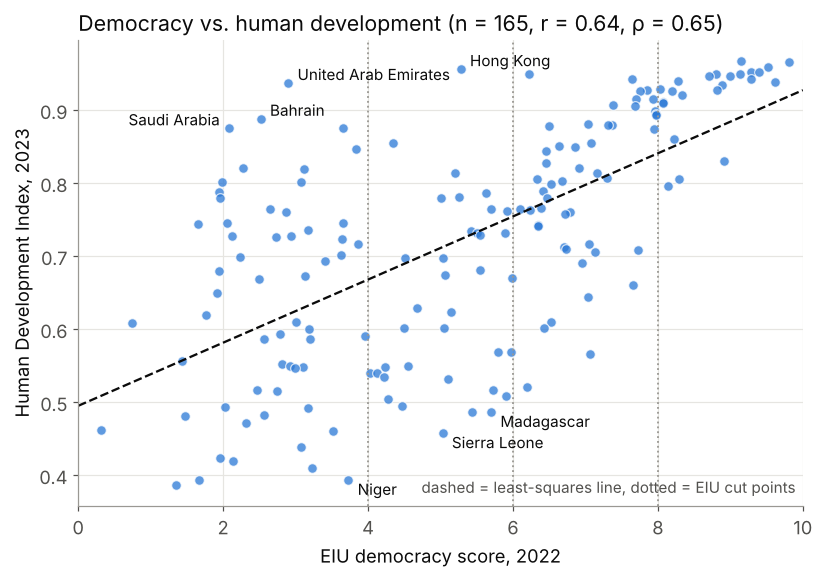

In [17]:
pairs = latest.join(hdi_clean, on="Code", how="inner").filter(pl.col("HDI").is_not_null())
r = pairs.select(pl.corr("democracy_eiu", "HDI")).item()
rho = pairs.select(pl.corr("democracy_eiu", "HDI", method="spearman")).item()
print(f"n = {pairs.height} | Pearson r = {r:.2f} | Spearman rho = {rho:.2f}")
print(pairs.group_by("category").agg(pl.len().alias("n"), pl.col("HDI").median().round(3).alias("median HDI"),
                                     pl.col("HDI").min().alias("min"), pl.col("HDI").max().alias("max")).sort("category"))

# simple least-squares line, to find the countries furthest above and below it
x_mean, y_mean = pairs["democracy_eiu"].mean(), pairs["HDI"].mean()
slope = ((pairs["democracy_eiu"] - x_mean) * (pairs["HDI"] - y_mean)).sum() / ((pairs["democracy_eiu"] - x_mean) ** 2).sum()
intercept = y_mean - slope * x_mean
pairs = pairs.with_columns((pl.col("HDI") - (intercept + slope * pl.col("democracy_eiu"))).alias("residual"))
above = pairs.sort("residual", descending=True).head(4)
below = pairs.sort("residual").head(3)
print("furthest above the line:", above.select("Entity", "democracy_eiu", "HDI").rows())
print("furthest below the line:", below.select("Entity", "democracy_eiu", "HDI").rows())

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for cut in (4, 6, 8):
    ax.axvline(cut, color=GRAY, linestyle=":", linewidth=1.2)
ax.scatter(pairs["democracy_eiu"].to_list(), pairs["HDI"].to_list(), s=40, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.8)
ax.plot([0, 10], [intercept, intercept + slope * 10], color=INK, linewidth=1.5, linestyle="--")
for row in above.iter_rows(named=True):
    left = row["Entity"] == "Saudi Arabia"  # sits right under Bahrain, so label it on the other side
    ax.annotate(row["Entity"], (row["democracy_eiu"], row["HDI"]), xytext=(-6 if left else 6, 2), textcoords="offset points",
                ha="right" if left else "left", fontsize=10, color=INK)
for row in below.iter_rows(named=True):
    ax.annotate(row["Entity"], (row["democracy_eiu"], row["HDI"]), xytext=(6, -10), textcoords="offset points", fontsize=10, color=INK)
ax.text(0.99, 0.02, "dashed = least-squares line, dotted = EIU cut points", transform=ax.transAxes, va="bottom", ha="right", fontsize=10, color=MUTED)
ax.set_xlim(0, 10)
ax.set_xlabel("EIU democracy score, 2022")
ax.set_ylabel("Human Development Index, 2023")
ax.set_title(f"Democracy vs. human development (n = {pairs.height}, r = {r:.2f}, ρ = {rho:.2f})", loc="left")
save(fig, "r2_score_vs_hdi")
plt.show()

**What it shows:** a clear positive relationship (Pearson r = 0.64, Spearman ρ = 0.65, n = 165), but **it isn't a straight line**. Authoritarian and hybrid countries have almost the same median HDI (0.635 vs 0.626), and HDI only climbs once you cross into flawed democracies (0.806) and full democracies (0.939). The countries furthest above the line are rich Gulf autocracies (UAE, Bahrain, Saudi Arabia) plus Hong Kong. The ones furthest below are poorer democracies and hybrid regimes like Niger, Sierra Leone, and Madagascar.

**So what:** this is the core of RQ1. Democracy and development go together, which we expected. What I didn't expect is the **step shape**: below a score of about 6, more democracy doesn't come with more development at all. A single correlation would hide that. Also, the biggest exceptions are oil-rich states, which suggests a third factor (resource wealth) is involved.

**What next:** compare HDI across the four categories directly (box plots) instead of only reporting one correlation. Split by continent to see whether the step shows up everywhere. Find a GDP or natural-resource dataset to test the "oil wealth" explanation, or ask someone who studies political economy.

### 4.3 Democracy score vs. inequality loss (the mediating question)

inequality loss (%): n=150  mean=20.755  median=18.143  sd=11.614  IQR=9.556 to 32.439  min=4.752  max=43.003  skew=0.31
n = 150 | r(democracy, loss) = -0.56 | r(HDI, loss) = -0.90 | r(democracy, loss after removing HDI) = 0.22
highest loss: [('Comoros', 3.2, 43.0), ('Angola', 3.96, 41.8), ('Mozambique', 3.51, 41.4)]
lowest loss: [('Slovenia', 7.75, 4.8), ('Iceland', 9.52, 5.1), ('Czechia', 7.97, 5.3)]


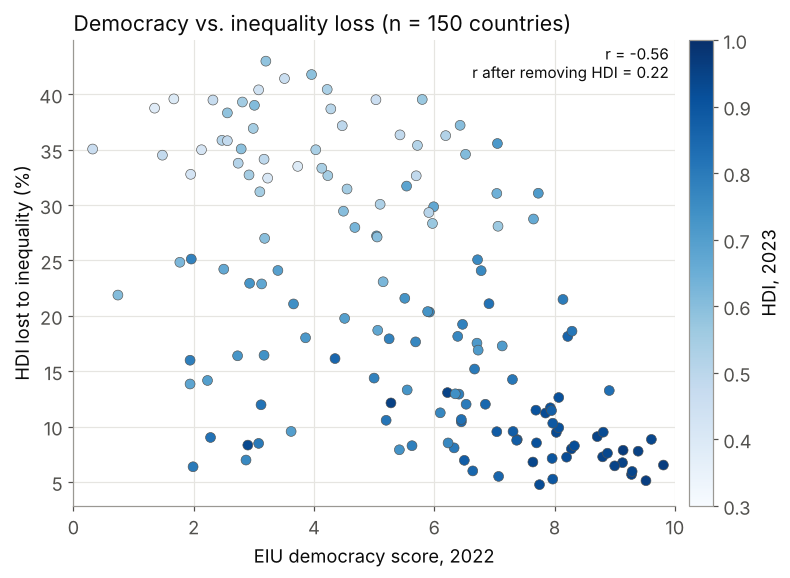

In [18]:
loss = (
    pairs.filter(pl.col("IHDI").is_not_null())
    .with_columns((100 * (1 - pl.col("IHDI") / pl.col("HDI"))).alias("inequality_loss"))
)
r_dem = loss.select(pl.corr("democracy_eiu", "inequality_loss")).item()
r_hdi = loss.select(pl.corr("HDI", "inequality_loss")).item()


def residuals(y, x):
    b = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
    return y - (y.mean() + b * (x - x.mean()))


partial = pl.DataFrame({
    "a": residuals(loss["democracy_eiu"], loss["HDI"]),
    "b": residuals(loss["inequality_loss"], loss["HDI"]),
}).select(pl.corr("a", "b")).item()
summarize(loss["inequality_loss"], "inequality loss (%)")
print(f"n = {loss.height} | r(democracy, loss) = {r_dem:.2f} | r(HDI, loss) = {r_hdi:.2f} | r(democracy, loss after removing HDI) = {partial:.2f}")
print("highest loss:", loss.sort("inequality_loss", descending=True).select("Entity", "democracy_eiu", pl.col("inequality_loss").round(1)).head(3).rows())
print("lowest loss:", loss.sort("inequality_loss").select("Entity", "democracy_eiu", pl.col("inequality_loss").round(1)).head(3).rows())

fig, ax = plt.subplots(figsize=(8.5, 5.5))
points = ax.scatter(loss["democracy_eiu"].to_list(), loss["inequality_loss"].to_list(), c=loss["HDI"].to_list(),
                    cmap="Blues", vmin=0.3, vmax=1.0, s=42, edgecolor="#52514e", linewidth=0.4)
bar = fig.colorbar(points, ax=ax, pad=0.02)
bar.set_label("HDI, 2023")
ax.text(0.99, 0.99, f"r = {r_dem:.2f}\nr after removing HDI = {partial:.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=10, color=INK)
ax.set_xlim(0, 10)
ax.set_xlabel("EIU democracy score, 2022")
ax.set_ylabel("HDI lost to inequality (%)")
ax.set_title(f"Democracy vs. inequality loss (n = {loss.height} countries)", loc="left")
save(fig, "r3_score_vs_inequality_loss")
plt.show()

**What it shows:** I measure inequality as the share of HDI lost to it, `1 - IHDI / HDI`. On its own, more democratic countries lose less (r = -0.56, n = 150). But inequality loss tracks HDI almost perfectly (r = -0.90), and the darker, high-HDI points all sit at the bottom right. Once HDI is taken out, the link between democracy and inequality loss **flips to slightly positive (r = 0.22)**. Comoros, Angola, and Mozambique lose over 40%, while Slovenia, Iceland, and Czechia lose about 5%.

**So what:** this is the "does inequality mediate" part of RQ1, and the answer so far is **not the way we framed it**. Democracy predicts lower inequality mainly because democracies are richer and more developed, not on its own. That was unexpected. It also comes with a caveat: 12 of the 15 countries missing IHDI are authoritarian, including four Gulf states, so this plot leaves out the countries that break the pattern in 4.2.

**What next:** in the modeling unit, fit HDI on democracy with and without inequality loss to test mediation properly instead of eyeballing it. Look for IHDI (or a Gini coefficient) for the missing Gulf states, so the sample isn't missing them.

### 4.4 Who backslid? Change from 2006 to 2022 vs. starting score

declined: 99 | improved: 66 | unchanged: 2 | median change: -0.17
r(starting score, change) = -0.07
shape: (4, 5)
┌──────────────────┬─────┬───────────────┬─────────────────────┬──────────┐
│ category_2006    ┆ n   ┆ median change ┆ mean size of change ┆ declined │
│ ---              ┆ --- ┆ ---           ┆ ---                 ┆ ---      │
│ enum             ┆ u32 ┆ f64           ┆ f64                 ┆ u32      │
╞══════════════════╪═════╪═══════════════╪═════════════════════╪══════════╡
│ Authoritarian    ┆ 55  ┆ 0.02          ┆ 0.74                ┆ 27       │
│ Hybrid regime    ┆ 33  ┆ -0.12         ┆ 1.11                ┆ 20       │
│ Flawed democracy ┆ 53  ┆ -0.21         ┆ 0.51                ┆ 36       │
│ Full democracy   ┆ 26  ┆ -0.19         ┆ 0.28                ┆ 16       │
└──────────────────┴─────┴───────────────┴─────────────────────┴──────────┘
biggest declines: [('Venezuela', -3.19), ('Nicaragua', -3.18), ('Mali', -2.76), ('Afghanistan', -2.74), ('Russia', -2.74)]
big

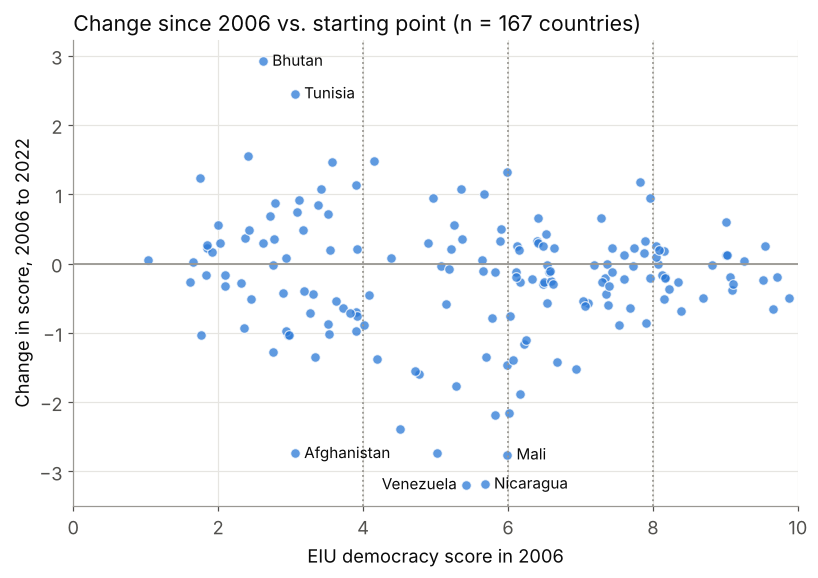

In [19]:
first_last = (
    countries.filter(pl.col("Year").is_in([2006, 2022]))
    .pivot(on="Year", index=["Entity", "Code"], values="democracy_eiu")
    .rename({"2006": "score_2006", "2022": "score_2022"})
    .with_columns((pl.col("score_2022") - pl.col("score_2006")).alias("change"))
    .join(countries.filter(pl.col("Year") == 2006).select("Entity", pl.col("category").alias("category_2006")), on="Entity")
)
print("declined:", first_last.filter(pl.col("change") < 0).height, "| improved:", first_last.filter(pl.col("change") > 0).height,
      "| unchanged:", first_last.filter(pl.col("change") == 0).height, "| median change:", round(first_last["change"].median(), 2))
print(f"r(starting score, change) = {first_last.select(pl.corr('score_2006', 'change')).item():.2f}")
print(first_last.group_by("category_2006").agg(
    pl.len().alias("n"),
    pl.col("change").median().round(2).alias("median change"),
    pl.col("change").abs().mean().round(2).alias("mean size of change"),
    (pl.col("change") < 0).sum().alias("declined"),
).sort("category_2006"))
print("biggest declines:", first_last.sort("change").select("Entity", pl.col("change").round(2)).head(5).rows())
print("biggest gains:", first_last.sort("change", descending=True).select("Entity", pl.col("change").round(2)).head(3).rows())

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.axhline(0, color=GRAY, linewidth=1.2)
for cut in (4, 6, 8):
    ax.axvline(cut, color=GRAY, linestyle=":", linewidth=1.2)
ax.scatter(first_last["score_2006"].to_list(), first_last["change"].to_list(), s=40, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.8)
for row in pl.concat([first_last.sort("change").head(4), first_last.sort("change", descending=True).head(2)]).iter_rows(named=True):
    left = row["Entity"] == "Venezuela"  # sits right next to Nicaragua, so label it on the other side
    ax.annotate(row["Entity"], (row["score_2006"], row["change"]), xytext=(-6 if left else 6, -3), textcoords="offset points",
                ha="right" if left else "left", fontsize=10, color=INK)
ax.set_xlim(0, 10)
ax.set_xlabel("EIU democracy score in 2006")
ax.set_ylabel("Change in score, 2006 to 2022")
ax.set_title(f"Change since 2006 vs. starting point (n = {first_last.height} countries)", loc="left")
save(fig, "r4_change_vs_start")
plt.show()

**What it shows:** more countries declined (99) than improved (66) between 2006 and 2022, with a median change of -0.17. The starting score barely predicts the direction of change (r = -0.07), but it does predict **how much a country moves**. Countries that started as hybrid regimes moved the most (average size of change 1.11 points), while full democracies barely moved (0.28). The biggest declines are Venezuela, Nicaragua, Mali, Afghanistan, and Russia, and four of those five started as hybrid regimes. The biggest gains are Bhutan and Tunisia.

**So what:** this is the outcome RQ2 wants to predict ("shifts or regressions in democracy scores"). Backsliding is common, and it's concentrated in the unstable middle, not in established democracies. We expected a downward trend, but it was a surprise how flat the full democracies are compared with hybrid regimes.

**What next:** to actually predict these drops we need cross-country election data with turnout and electoral systems. **Our `elections.csv` only has U.S. presidential results** (see below), so it can't be joined to this file. A dataset like International IDEA's Voter Turnout Database would cover it. We should also check whether the big drops happen right around election years.

## 5-6. Revised research questions

What the data changed:

- **RQ1 (revised):** *How strongly is a country's EIU democracy score related to its HDI and IHDI in 2022-2023, and does the relationship change at the "flawed democracy" threshold (score 6)?*
  - **Why:** the HDI file only has 2023, so this has to be a single-year comparison, not a trend. The relationship in 4.2 is a step, not a line. And 4.3 shows that inequality loss mostly tracks HDI, so the mediation test has to control for HDI.
- **RQ2 (proposed revision, needs group sign-off):** *Which countries and regions backslid between 2006 and 2022, and are hybrid regimes more volatile than established democracies?*
  - **Why:** `elections.csv` is U.S. presidential results from 1824 to 2024 (one row per candidate), not the national turnout and electoral-system data described in Checkpoint 3. It can't be joined to the EIU panel. If we find a cross-national turnout dataset, the original RQ2 can come back.

**Notes for the group:**

- `democracy-eiu.csv` and `democracy-index-eiu.csv` are the same EIU data (every country row matches exactly; the second file just adds 2023), and neither has sub-scores. We should keep one and update the Checkpoint 3 description.
- Remove the World and continent rows before any country-level analysis (105 rows).
- Join on `Code`, not on country names, and cast `IHDI` to a number.

# Part 2: Don - Democracy Index EDA

# EDA: `democracy-index-eiu.csv` (Daunovan)

We split this checkpoint by CSV, and this one is mine: the **EIU Democracy Index** panel, where one row is one country (or region) in one year with a score from 0 to 10. This notebook covers all six steps for this file: the profile, anomalies, distributions, relationships, "so what?", and "what next?".

Our research questions, from the Checkpoint 3 README:

- **RQ1 (primary):** How strongly does a country's level of democracy correlate with its Human Development Index (HDI) and inequality-adjusted HDI (IHDI) across regions, and does inequality play a mediating role?
- **RQ2 (secondary):** Can election dynamics like turnout and electoral system changes act as early indicators of shifts or declines in a country's democracy score?

For the relationship plots I join to `hdi-ihdi-democracy-by-country.csv` (our secondary dataset) on the country code, and I cross-check against `democracy-index-eiu.csv`.

In [1]:
from pathlib import Path

import polars as pl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(160)

DATA = Path("..")          # the CSVs live in the repo root
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)

BLUE = "#2a78d6"
INK = "#0b0b0b"
MUTED = "#52514e"
GRAY = "#9a9893"
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRAY,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
})


def save(fig, name):
    fig.savefig(FIGS / f"daunovan_{name}.png", bbox_inches="tight", dpi=150)


eiu_index = pl.read_csv(DATA / "democracy-index-eiu.csv")        # Daunovan's file
eiu = pl.read_csv(DATA / "democracy-eiu.csv")                    # Daniel's file
hdi = pl.read_csv(DATA / "hdi-ihdi-democracy-by-country.csv")    # Kam's file, used for the join

## 1. Profile

In [2]:
print("shape:", eiu_index.shape)

shape: (2765, 4)


In [3]:
eiu_index.glimpse()

Rows: 2765
Columns: 4
$ Entity          <str> 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan'
$ Code            <str> 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG'
$ Year            <i64> 2006, 2008, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017
$ Democracy score <f64> 3.06, 3.02, 2.48, 2.48, 2.48, 2.48, 2.77, 2.77, 2.55, 2.55



In [4]:
eiu_index.null_count()

Entity,Code,Year,Democracy score
u32,u32,u32,u32
0,96,0,0


In [5]:
eiu_index.describe()

statistic,Entity,Code,Year,Democracy score
str,str,str,f64,f64
"""count""","""2765""","""2669""",2765.0,2765.0
"""null_count""","""0""","""96""",0.0,0.0
"""mean""",null,null,2015.259675,5.500987
"""std""",null,null,4.897042,2.191708
"""min""","""Afghanistan""","""AFG""",2006.0,0.32
"""25%""",null,null,2011.0,3.53
"""50%""",null,null,2015.0,5.79
"""75%""",null,null,2019.0,7.24
"""max""","""Zimbabwe""","""ZWE""",2023.0,9.93


In [6]:
print("entities:", eiu_index["Entity"].n_unique(), "| codes:", eiu_index["Code"].n_unique())
print("rows per entity:", eiu_index.group_by("Entity").agg(pl.len())["len"].unique().to_list())
print("years:", eiu_index["Year"].unique().sort().to_list())

entities: 174 | codes: 169
rows per entity: [15, 16]
years: [2006, 2008, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]


In [7]:
# what are the entities with no country codes?
eiu_index.filter(
    pl.col("Code").is_null() | pl.col("Code").str.starts_with("OWID_")
).unique(subset="Entity")

Entity,Code,Year,Democracy score
str,str,i64,f64
"""North America""",null,2006,6.5664287
"""Africa""",null,2006,4.1094
"""Europe""",null,2006,7.74925
"""Asia""",null,2006,4.3789363
"""World""","""OWID_WRL""",2006,5.5192814
"""South America""",null,2006,6.52
"""Oceania""",null,2006,7.575


In [8]:
eiu_index.sample(5)

Entity,Code,Year,Democracy score
str,str,i64,f64
"""Argentina""","""ARG""",2019,7.02
"""Chile""","""CHL""",2006,7.89
"""Jamaica""","""JAM""",2015,7.39
"""Oman""","""OMN""",2022,3.12
"""Spain""","""ESP""",2013,8.02


In [9]:
# Select one Entity with 15 rows and one with 16 rows
selected = (
    eiu_index
    .group_by("Entity")
    .agg(n=pl.len())
    .filter(pl.col("n").is_in([15, 16]))
    .group_by("n")
    .first()
    .sort("n")
)

# Display the selected entities and their row counts
print(selected)

# Retrieve all original rows for those entities
sample = (
    eiu_index
    .join(selected.select("Entity"), on="Entity", how="inner")
    .sort("Entity")
)

# ensure polars prints the whole table so that we can see everything
with pl.Config(tbl_rows=-1):
    print(sample)

# Get years from the entity with 16 rows
years_16 = (
    sample
    .join(selected, on="Entity")
    .filter(pl.col("n") == 16)
    .get_column("Year")
)

# Get years from the entity with 15 rows
years_15 = (
    sample
    .join(selected, on="Entity")
    .filter(pl.col("n") == 15)
    .get_column("Year")
)

# Print years present in the 16-row entity but not the 15-row entity
print("Year not common in both is", years_16.filter(~years_16.is_in(years_15.implode())).first())

shape: (2, 2)
┌─────┬─────────────┐
│ n   ┆ Entity      │
│ --- ┆ ---         │
│ u32 ┆ str         │
╞═════╪═════════════╡
│ 15  ┆ North Korea │
│ 16  ┆ Georgia     │
└─────┴─────────────┘
shape: (31, 4)
┌─────────────┬──────┬──────┬─────────────────┐
│ Entity      ┆ Code ┆ Year ┆ Democracy score │
│ ---         ┆ ---  ┆ ---  ┆ ---             │
│ str         ┆ str  ┆ i64  ┆ f64             │
╞═════════════╪══════╪══════╪═════════════════╡
│ Georgia     ┆ GEO  ┆ 2006 ┆ 4.9             │
│ Georgia     ┆ GEO  ┆ 2008 ┆ 4.62            │
│ Georgia     ┆ GEO  ┆ 2010 ┆ 4.59            │
│ Georgia     ┆ GEO  ┆ 2011 ┆ 4.74            │
│ Georgia     ┆ GEO  ┆ 2012 ┆ 5.53            │
│ Georgia     ┆ GEO  ┆ 2013 ┆ 5.95            │
│ Georgia     ┆ GEO  ┆ 2014 ┆ 5.82            │
│ Georgia     ┆ GEO  ┆ 2015 ┆ 5.88            │
│ Georgia     ┆ GEO  ┆ 2016 ┆ 5.93            │
│ Georgia     ┆ GEO  ┆ 2017 ┆ 5.93            │
│ Georgia     ┆ GEO  ┆ 2018 ┆ 5.5             │
│ Georgia     ┆ GEO  ┆ 2019

**What stands out:**

- **2,765 rows × 4 columns** (`Entity`, `Code`, `Year`, `Democracy score`), with 174 entities with 15 to 16 rows each.
  - The differing row counts are because some Entities are missing data for 2023.
- The years are **2006, 2008, and 2010 to 2022**. 2007 and 2009 aren't there, and nothing goes past 2022 even though our Checkpoint 3 README says "2006 through 2023".
- `Code` is missing for 96 rows. Those turn out to be continent rows (Africa, Asia, ...), not countries, so only 167 of the 174 entities are actually countries.
- Scores run from 0.32 to 9.93 on the 0 to 10 scale, so nothing is out of range. The median (5.79) is higher than the mean (5.5), so there's a slightly longer tail at the low end.

## 2. Anomalies

I checked for the six issue types from Week 3 (missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units), plus issues that show up when this file is compared or joined with our other CSVs. The full table is at the end of this section.

### 2a. Region rows mixed in with countries

In [16]:
is_aggregate = pl.col("Code").is_null() | pl.col("Code").str.starts_with("OWID_")
aggregates = eiu_index.filter(is_aggregate)
print("aggregate rows:", aggregates.height, "| entities:", sorted(aggregates["Entity"].unique().to_list()))
print("rows with no Code:", eiu_index["Code"].null_count(), "| rows with a non-ISO OWID_ code:", eiu_index.filter(pl.col("Code").str.starts_with("OWID_")).height)

countries = eiu_index.filter(~is_aggregate)
for year in [2006, 2022]:
    world_row = eiu_index.filter((pl.col("Entity") == "World") & (pl.col("Year") == year))["Democracy score"].item()
    country_mean = countries.filter(pl.col("Year") == year)["Democracy score"].mean()
    print(f"{year}: World row = {world_row:.4f} | plain mean of the 167 countries = {country_mean:.4f}")

aggregate rows: 112 | entities: ['Africa', 'Asia', 'Europe', 'North America', 'Oceania', 'South America', 'World']
rows with no Code: 96 | rows with a non-ISO OWID_ code: 16
2006: World row = 5.5193 | plain mean of the 167 countries = 5.5193
2022: World row = 5.2932 | plain mean of the 167 countries = 5.2932


"World" is just the plain average of the 167 countries, and the continent rows are averages too. Leaving them in would count every country twice. I **removed them from the country table**, but I kept them in their own table for the region plot in step 4.

### 2b. Missing years

In [20]:
all_years = list(range(2006, 2023))
missing_years = sorted(set(all_years) - set(eiu_index["Year"].unique().to_list()))
print("missing years:", missing_years, "->", countries["Entity"].n_unique() * len(missing_years), "country-years absent")

missing years: [2007, 2009] -> 334 country-years absent


### 2c. Formatting, repeated values, and clean checks

In [22]:
keys = ["Entity", "Code"]
extra_decimals = (pl.col("Democracy score") * 100 - (pl.col("Democracy score") * 100).round(0)).abs() > 1e-9
print("values with more than 2 decimals:", eiu_index.filter(extra_decimals).height, "| in country rows:", eiu_index.filter(extra_decimals & ~is_aggregate).height)

changes = (
    countries.sort("Entity", "Year")
    .with_columns(
        pl.col("Democracy score").diff().over("Entity").alias("change"),
        pl.col("Year").diff().over("Entity").alias("years_apart"),
    )
)
annual = changes.filter(pl.col("years_apart") == 1)
print(f"one-year changes: {annual.height} | exactly 0: \
    {annual.filter(pl.col('change') == 0).height} \
    ({annual.filter(pl.col('change') == 0).height / annual.height:.1%})")

print("\n-- clean checks --")
print("exact duplicate rows:", eiu_index.is_duplicated().sum(), "| duplicate (Entity, Year):", eiu_index.select(pl.struct(keys).is_duplicated().sum()).item())
print("scores outside 0-10:", eiu_index.filter(~pl.col("Democracy score").is_between(0, 10)).height)
print("names with extra spaces:", eiu_index.filter(pl.col("Entity") != pl.col("Entity").str.strip_chars()).height)
print("country codes that aren't 3 letters:", countries.filter(pl.col("Code").str.len_chars() != 3).height)

values with more than 2 decimals: 106 | in country rows: 0
one-year changes: 2152 | exactly 0:     741     (34.4%)

-- clean checks --
exact duplicate rows: 0 | duplicate (Entity, Year): 2765
scores outside 0-10: 0
names with extra spaces: 0
country codes that aren't 3 letters: 0


### 2d. Cleaned table and anomaly summary

In [27]:
CATEGORIES = ["Authoritarian", "Hybrid regime", "Flawed democracy", "Full democracy"]
category = pl.Enum(CATEGORIES)
# eiu_index's own cut points: <= 4 authoritarian, 4-6 hybrid, 6-8 flawed, > 8 full
countries = countries.with_columns(
    pl.when(pl.col("Democracy score") > 8).then(pl.lit("Full democracy"))
    .when(pl.col("Democracy score") > 6).then(pl.lit("Flawed democracy"))
    .when(pl.col("Democracy score") > 4).then(pl.lit("Hybrid regime"))
    .otherwise(pl.lit("Authoritarian"))
    .cast(category)
    .alias("category")
)
regions = aggregates.select("Entity", "Year", "Democracy score")
print("countries:", countries.shape, "| unique countries:", countries["Entity"].n_unique(), "| region rows kept aside:", regions.shape)

anomalies = pl.DataFrame(
    [
        ("World and continent averages mixed in with countries", "Mixed granularity", f"{aggregates.height}", "Removed from the country table; kept separately for the region plot"),
        ("No Code for the 6 continent rows", "Missing values", f"{eiu_index['Code'].null_count()}", "Resolved by removing the averages"),
        ("World uses the non-ISO code OWID_WRL", "Inconsistent formatting", f"{eiu_index.filter(pl.col('Code').str.starts_with('OWID_')).height}", "Resolved by removing the averages"),
        ("No 2007 or 2009 (eiu_index wasn't annual before 2010)", "Missing years", f"{countries['Entity'].n_unique() * len(missing_years)} country-years", "Left; year-to-year changes only use back-to-back years"),
        ("Extra decimals in the region averages", "Inconsistent formatting", f"{eiu_index.filter(extra_decimals).height}", "Resolved by removing the averages"),
        ("Score unchanged from one year to the next", "Looked stale, isn't", f"{annual.filter(pl.col('change') == 0).height} of {annual.height} changes", "Left; eiu_index only changes a score when something happens"),
    ],
    schema=["anomaly", "type", "rows affected", "what I did"],
    orient="row",
)
with pl.Config(fmt_str_lengths=90, tbl_width_chars=250, tbl_rows=20):
    print(anomalies)

countries: (2653, 5) | unique countries: 167 | region rows kept aside: (112, 3)
shape: (6, 4)
┌───────────────────────────────────────────────────────┬─────────────────────────┬─────────────────────┬─────────────────────────────────────────────────────────────────────┐
│ anomaly                                               ┆ type                    ┆ rows affected       ┆ what I did                                                          │
│ ---                                                   ┆ ---                     ┆ ---                 ┆ ---                                                                 │
│ str                                                   ┆ str                     ┆ str                 ┆ str                                                                 │
╞═══════════════════════════════════════════════════════╪═════════════════════════╪═════════════════════╪═════════════════════════════════════════════════════════════════════╡
│ World and continent aver

No duplicate rows or keys, no scores outside 0 to 10, and no stray spaces. 

## 3. Distributions

The main feature is `Democracy score`. I look at it in the latest year that has all countries (2022, 167 countries), as EIU's four categories, and as year-to-year changes. 

In [28]:
def summarize(s, label):
    print(f"{label}: n={s.len()}  mean={s.mean():.3f}  median={s.median():.3f}  sd={s.std():.3f}  "
          f"IQR={s.quantile(0.25):.3f} to {s.quantile(0.75):.3f}  min={s.min():.3f}  max={s.max():.3f}  skew={s.skew():.2f}")


latest = countries.filter(pl.col("Year") == 2022)

### 3.1 Democracy score, 2022

score 2022: n=167  mean=5.293  median=5.540  sd=2.376  IQR=3.120 to 7.130  min=0.320  max=9.810  skew=-0.04
lowest: [('Afghanistan', 0.32), ('Myanmar', 0.74), ('North Korea', 1.08)]
highest: [('Norway', 9.81), ('New Zealand', 9.61), ('Iceland', 9.52)]
countries per 1-point bin: [(0.0, 2), (1.0, 13), (2.0, 23), (3.0, 21), (4.0, 11), (5.0, 25), (6.0, 25), (7.0, 23), (8.0, 15), (9.0, 9)]


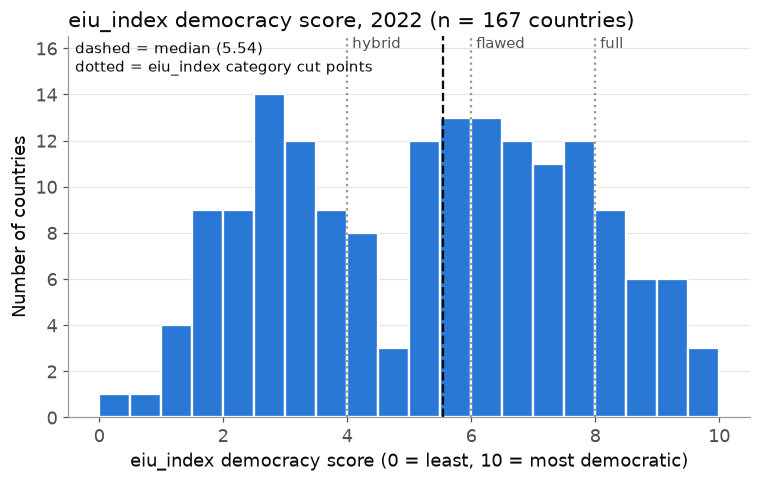

In [29]:
summarize(latest["Democracy score"], "score 2022")
print("lowest:", latest.sort("Democracy score").select("Entity", "Democracy score").head(3).rows())
print("highest:", latest.sort("Democracy score", descending=True).select("Entity", "Democracy score").head(3).rows())
print("countries per 1-point bin:", latest.with_columns(pl.col("Democracy score").floor().clip(0, 9).alias("bin")).group_by("bin").agg(pl.len()).sort("bin").rows())

fig, ax = plt.subplots()
ax.hist(latest["Democracy score"].to_list(), bins=[i / 2 for i in range(21)], color=BLUE, edgecolor="white", linewidth=1.5)
for cut, label in [(4, "hybrid"), (6, "flawed"), (8, "full")]:
    ax.axvline(cut, color=GRAY, linestyle=":", linewidth=1.5)
    ax.text(cut + 0.08, 1, label, transform=ax.get_xaxis_transform(), va="top", color=MUTED, fontsize=10)
ax.axvline(latest["Democracy score"].median(), color=INK, linestyle="--", linewidth=1.5)
ax.text(0.01, 0.99, f"dashed = median ({latest['Democracy score'].median():.2f})\ndotted = eiu_index category cut points",
        transform=ax.transAxes, va="top", ha="left", fontsize=10, color=INK)
ax.margins(y=0.18)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x", visible=False)
ax.set_xlabel("eiu_index democracy score (0 = least, 10 = most democratic)")
ax.set_ylabel("Number of countries")
ax.set_title(f"eiu_index democracy score, 2022 (n = {latest.height} countries)", loc="left")
save(fig, "d1_score_2022")
plt.show()

**Shape:** a very wide spread (SD 2.38, IQR 3.12 to 7.13) across almost the whole 0 to 10 range. The center is median 5.54, mean 5.29, and the skew is about 0 (-0.04). It isn't one bell, though. There's a cluster of authoritarian scores from 2 to 4 (44 countries), a thin middle from 4 to 5 (11 countries), and a bigger cluster from 5 to 8 (73 countries). Afghanistan (0.32), Myanmar (0.74), and North Korea (1.08) are at the bottom, and Norway (9.81) is at the top. No point is an outlier by the 1.5 × IQR rule.

**Why it matters:** with two clusters and a gap in between, "the average country" isn't meaningful. Comparing groups (categories or regions) will be more honest for RQ1 than averages.

### 3.2 EIU category, 2022

shape: (4, 2)
┌──────────────────┬───────────┐
│ category         ┆ countries │
│ ---              ┆ ---       │
│ enum             ┆ u32       │
╞══════════════════╪═══════════╡
│ Authoritarian    ┆ 59        │
│ Hybrid regime    ┆ 36        │
│ Flawed democracy ┆ 48        │
│ Full democracy   ┆ 24        │
└──────────────────┴───────────┘


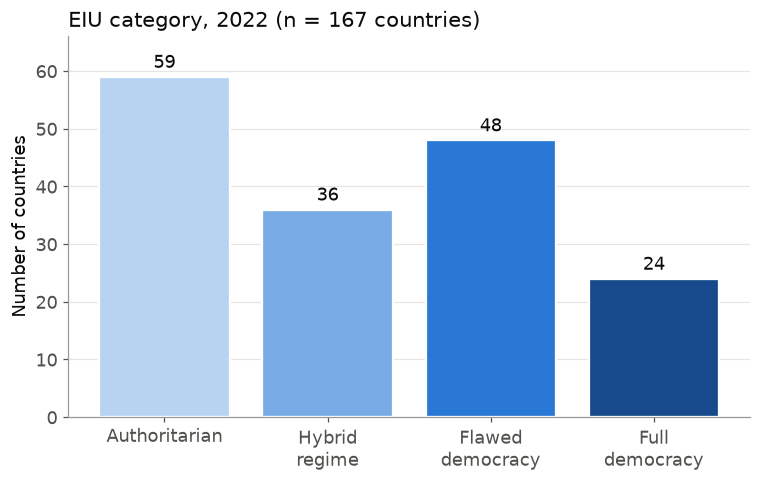

In [30]:
category_counts = latest.group_by("category").agg(pl.len().alias("countries")).sort("category")
print(category_counts)

fig, ax = plt.subplots()
shades = ["#b7d3f2", "#79abe6", "#2a78d6", "#174a8c"]  # one hue, light to dark, because the categories are ordered
labels = [c.replace(" ", "\n", 1) for c in category_counts["category"].cast(pl.String).to_list()]
bars = ax.bar(labels, category_counts["countries"].to_list(), color=shades, edgecolor="white", linewidth=1.5)
ax.bar_label(bars, padding=3, color=INK, fontsize=12)
ax.margins(y=0.12)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Number of countries")
ax.set_title(f"EIU category, 2022 (n = {latest.height} countries)", loc="left")
save(fig, "d2_category_2022")
plt.show()

**Shape:** this is an ordered category, so it gets a bar chart. **Authoritarian is the most common category (59)**, followed by flawed democracy (48), hybrid regime (36), and full democracy (24). Only about 14% of countries are full democracies, and 95 of 167 (57%) fall below the "flawed democracy" line. These counts match the totals EIU itself reported for 2022, which is a good sign the file is complete.

**Why it matters:** for RQ1, the categories give us four groups to compare HDI across (I do that in 4.2), and the groups are big enough to do it (full democracies are the smallest with 24, or 23 after the HDI join).

### 3.3 Year-to-year change in score

one-year change: n=2152  mean=-0.018  median=0.000  sd=0.237  IQR=-0.070 to 0.050  min=-2.530  max=2.740  skew=0.17
exactly 0: 741 | bigger than 1 point either way: 18
biggest drops: [('Afghanistan', 2021, -2.53), ('Myanmar', 2021, -2.02), ('Libya', 2015, -1.55), ('Niger', 2023, -1.36)]
biggest gains: [('Tunisia', 2011, 2.74), ('Fiji', 2014, 2.0), ('Thailand', 2019, 1.69), ('Libya', 2011, 1.61)]


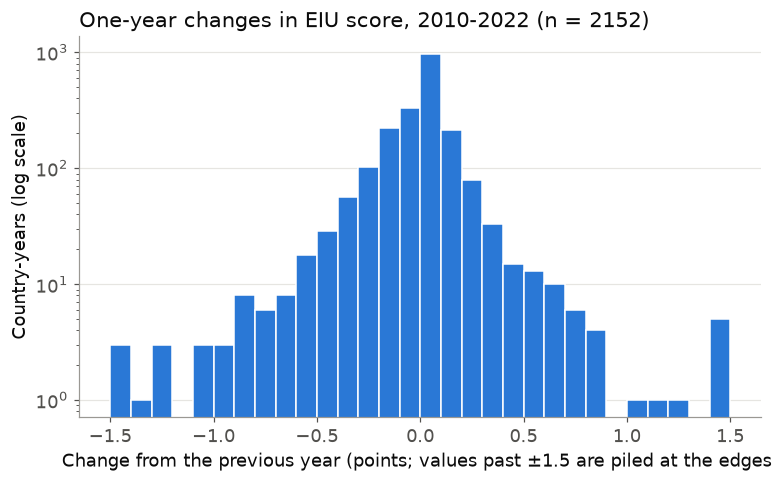

In [31]:
summarize(annual["change"], "one-year change")
print("exactly 0:", annual.filter(pl.col("change") == 0).height, "| bigger than 1 point either way:", annual.filter(pl.col("change").abs() > 1).height)
print("biggest drops:", annual.sort("change").select("Entity", "Year", pl.col("change").round(2)).head(4).rows())
print("biggest gains:", annual.sort("change", descending=True).select("Entity", "Year", pl.col("change").round(2)).head(4).rows())

fig, ax = plt.subplots()
clipped = annual["change"].clip(-1.5, 1.5)
ax.hist(clipped.to_list(), bins=[-1.5 + i * 0.1 for i in range(31)], color=BLUE, edgecolor="white", linewidth=1)
ax.set_yscale("log")
ax.set_xlabel("Change from the previous year (points; values past ±1.5 are piled at the edges)")
ax.set_ylabel("Country-years (log scale)")
ax.grid(axis="x", visible=False)
ax.set_title(f"One-year changes in EIU score, 2010-2022 (n = {annual.height})", loc="left")
save(fig, "d3_annual_change")
plt.show()

**Shape:** a huge spike at 0, since 33.9% of one-year changes are exactly zero. Around it the distribution is narrow (IQR -0.07 to 0.05, median 0) with **long tails**, so I used a log scale to make the rare big moves visible. Only 16 of 2,004 changes are bigger than 1 point. The biggest are Afghanistan's 2021 drop (-2.53), Myanmar's 2021 drop (-2.02), and Tunisia's 2011 jump (+2.74), which are a takeover, a coup, and a revolution. The mean is slightly negative (-0.014), so scores drift down a little over time.

**Why it matters:** most of the "action" for RQ2 is in a small number of big jumps that line up with real events. A model that predicts change will mostly be predicting zero, so we should probably focus on the big moves.

## 4. Relationships

Four plots. 4.1 uses the region rows from this file, and 4.2 and 4.3 use the join with the HDI file.

### 4.1 Democracy over time by continent

World: [(2006, 5.52), (2008, 5.55), (2010, 5.46), (2011, 5.49), (2012, 5.52), (2013, 5.53), (2014, 5.55), (2015, 5.55), (2016, 5.52), (2017, 5.48), (2018, 5.48), (2019, 5.44), (2020, 5.37), (2021, 5.28), (2022, 5.29), (2023, 5.69)]
Europe: 7.75 (2006) -> 7.54 (2022), change -0.21
Oceania: 7.58 (2006) -> 7.46 (2022), change -0.11
South America: 6.52 (2006) -> 6.11 (2022), change -0.41
North America: 6.57 (2006) -> 5.67 (2022), change -0.89
Asia: 4.38 (2006) -> 4.96 (2022), change +0.58
Africa: 4.11 (2006) -> 4.34 (2022), change +0.23


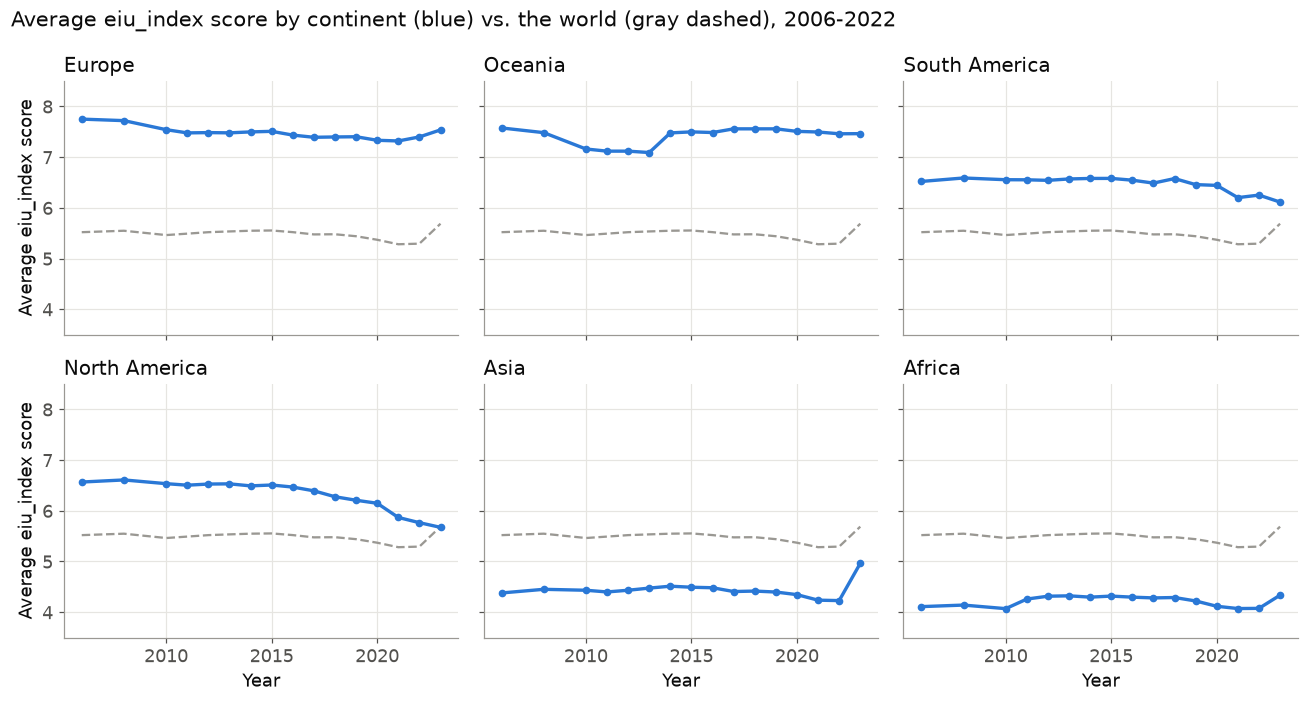

In [33]:
CONTINENTS = ["Europe", "Oceania", "South America", "North America", "Asia", "Africa"]
world = regions.filter(pl.col("Entity") == "World").sort("Year")
print("World:", world.select("Year", pl.col("Democracy score").round(2)).rows())
for name in CONTINENTS:
    s = regions.filter(pl.col("Entity") == name).sort("Year")["Democracy score"]
    print(f"{name}: {s[0]:.2f} (2006) -> {s[-1]:.2f} (2022), change {s[-1] - s[0]:+.2f}")

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)
for ax, name in zip(axes.flat, CONTINENTS):
    s = regions.filter(pl.col("Entity") == name).sort("Year")
    ax.plot(world["Year"].to_list(), world["Democracy score"].to_list(), color=GRAY, linestyle="--", linewidth=1.5)
    ax.plot(s["Year"].to_list(), s["Democracy score"].to_list(), color=BLUE, linewidth=2.2, marker="o", markersize=4)
    ax.set_title(name, loc="left", fontsize=13)
    ax.set_ylim(3.5, 8.5)
for ax in axes[1]:
    ax.set_xlabel("Year")
for ax in axes[:, 0]:
    ax.set_ylabel("Average eiu_index score")
fig.suptitle("Average eiu_index score by continent (blue) vs. the world (gray dashed), 2006-2022", x=0.01, ha="left", fontsize=14)
fig.tight_layout()
save(fig, "r1_continents_over_time")
plt.show()

**What it shows:** the world average climbs a little to a peak of 5.55 in 2015, then falls to 5.29 by 2022, with the steepest drop between 2019 and 2021. Every continent ends lower than it started. **North America falls the most (6.57 to 5.76)**, then South America (-0.27), Europe (-0.35), Asia (-0.15), Oceania (-0.12), and Africa, which is almost flat (4.11 to 4.07). The gaps between continents are much bigger than any change over time: Europe and Oceania stay around 7.5, while Africa and Asia stay around 4 to 4.5.

**So what:** this is the "across regions" part of RQ1. Region explains a lot of the variation in democracy, so any democracy-HDI link could partly be a region effect. The overall decline was expected, since the mid-2010s "democratic recession" is well known. North America falling the most was **unexpected**. OWID's "North America" includes Central America and the Caribbean, so countries like Nicaragua (-3.18) are probably driving it, not the US or Canada.

**What next:** split North America into US and Canada vs. Central America and the Caribbean. Also, these continent rows are unweighted averages (each country counts the same), so check whether a population-weighted version tells the same story.

### 4.4 Who backslid? Change from 2006 to 2022 vs. starting score

declined: 99 | improved: 66 | unchanged: 2 | median change: -0.17
r(starting score, change) = -0.07
shape: (4, 5)
┌──────────────────┬─────┬───────────────┬─────────────────────┬──────────┐
│ category_2006    ┆ n   ┆ median change ┆ mean size of change ┆ declined │
│ ---              ┆ --- ┆ ---           ┆ ---                 ┆ ---      │
│ enum             ┆ u32 ┆ f64           ┆ f64                 ┆ u32      │
╞══════════════════╪═════╪═══════════════╪═════════════════════╪══════════╡
│ Authoritarian    ┆ 55  ┆ 0.02          ┆ 0.74                ┆ 27       │
│ Hybrid regime    ┆ 33  ┆ -0.12         ┆ 1.11                ┆ 20       │
│ Flawed democracy ┆ 53  ┆ -0.21         ┆ 0.51                ┆ 36       │
│ Full democracy   ┆ 26  ┆ -0.19         ┆ 0.28                ┆ 16       │
└──────────────────┴─────┴───────────────┴─────────────────────┴──────────┘
biggest declines: [('Venezuela', -3.19), ('Nicaragua', -3.18), ('Mali', -2.76), ('Afghanistan', -2.74), ('Russia', -2.74)]
big

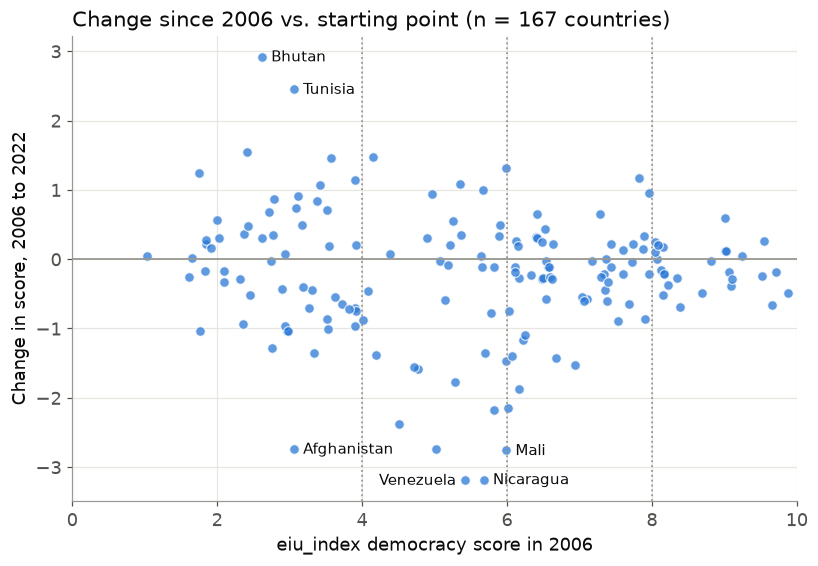

In [34]:
first_last = (
    countries.filter(pl.col("Year").is_in([2006, 2022]))
    .pivot(on="Year", index=["Entity", "Code"], values="Democracy score")
    .rename({"2006": "score_2006", "2022": "score_2022"})
    .with_columns((pl.col("score_2022") - pl.col("score_2006")).alias("change"))
    .join(countries.filter(pl.col("Year") == 2006).select("Entity", pl.col("category").alias("category_2006")), on="Entity")
)
print("declined:", first_last.filter(pl.col("change") < 0).height, "| improved:", first_last.filter(pl.col("change") > 0).height,
      "| unchanged:", first_last.filter(pl.col("change") == 0).height, "| median change:", round(first_last["change"].median(), 2))
print(f"r(starting score, change) = {first_last.select(pl.corr('score_2006', 'change')).item():.2f}")
print(first_last.group_by("category_2006").agg(
    pl.len().alias("n"),
    pl.col("change").median().round(2).alias("median change"),
    pl.col("change").abs().mean().round(2).alias("mean size of change"),
    (pl.col("change") < 0).sum().alias("declined"),
).sort("category_2006"))
print("biggest declines:", first_last.sort("change").select("Entity", pl.col("change").round(2)).head(5).rows())
print("biggest gains:", first_last.sort("change", descending=True).select("Entity", pl.col("change").round(2)).head(3).rows())

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.axhline(0, color=GRAY, linewidth=1.2)
for cut in (4, 6, 8):
    ax.axvline(cut, color=GRAY, linestyle=":", linewidth=1.2)
ax.scatter(first_last["score_2006"].to_list(), first_last["change"].to_list(), s=40, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.8)
for row in pl.concat([first_last.sort("change").head(4), first_last.sort("change", descending=True).head(2)]).iter_rows(named=True):
    left = row["Entity"] == "Venezuela"  # sits right next to Nicaragua, so label it on the other side
    ax.annotate(row["Entity"], (row["score_2006"], row["change"]), xytext=(-6 if left else 6, -3), textcoords="offset points",
                ha="right" if left else "left", fontsize=10, color=INK)
ax.set_xlim(0, 10)
ax.set_xlabel("eiu_index democracy score in 2006")
ax.set_ylabel("Change in score, 2006 to 2022")
ax.set_title(f"Change since 2006 vs. starting point (n = {first_last.height} countries)", loc="left")
save(fig, "r4_change_vs_start")
plt.show()

**What it shows:** more countries declined (99) than improved (66) between 2006 and 2022, with a median change of -0.17. The starting score barely predicts the direction of change (r = -0.07), but it does predict **how much a country moves**. Countries that started as hybrid regimes moved the most (average size of change 1.11 points), while full democracies barely moved (0.28). The biggest declines are Venezuela, Nicaragua, Mali, Afghanistan, and Russia, and four of those five started as hybrid regimes. The biggest gains are Bhutan and Tunisia.

**So what:** this is the outcome RQ2 wants to predict ("shifts or regressions in democracy scores"). Backsliding is common, and it's concentrated in the unstable middle, not in established democracies. We expected a downward trend, but it was a surprise how flat the full democracies are compared with hybrid regimes.

**What next:** to actually predict these drops we need cross-country election data with turnout and electoral systems. **Our `elections.csv` only has U.S. presidential results** (see below), so it can't be joined to this file. A dataset like International IDEA's Voter Turnout Database would cover it. We should also check whether the big drops happen right around election years.

## 5-6. Revised research questions

What the data changed:

- **RQ1 (revised):** *How strongly is a country's EIU democracy score related to its HDI and IHDI in 2022-2023, and does the relationship change at the "flawed democracy" threshold (score 6)?*
  - **Why:** the HDI file only has 2023, so this has to be a single-year comparison, not a trend. The relationship in 4.2 is a step, not a line. And 4.3 shows that inequality loss mostly tracks HDI, so the mediation test has to control for HDI.
- **RQ2 (proposed revision, needs group sign-off):** *Which countries and regions backslid between 2006 and 2022, and are hybrid regimes more volatile than established democracies?*
  - **Why:** `elections.csv` is U.S. presidential results from 1824 to 2024 (one row per candidate), not the national turnout and electoral-system data described in Checkpoint 3. It can't be joined to the EIU panel. If we find a cross-national turnout dataset, the original RQ2 can come back.

**Notes for the group:**

- `democracy-eiu.csv` and `democracy-index-eiu.csv` are the same EIU data (every country row matches exactly; the second file just adds 2023), and neither has sub-scores. As such, I believe we should keep `democracy_index` and update the Checkpoint 3 description. Since the two files cover the same data, this section does not cover the relationships between `democracy_index` and `IHDI`.
- Remove the World and continent rows before any country-level analysis (105 rows).

# Part 3: Kamalaksha - HDI, IHDI, and Democracy EDA

# EDA: `hdi-ihdi-democracy-by-country.csv` (Kamalaksha)

This notebook looks at 2023 data for HDI, IHDI, and democracy scores by country.

I compare these scores to see how development and democracy are related. The charts show patterns in the data, but they do not prove that one causes the other.

I use `hdi-ihdi-democracy-by-country.csv` as the main dataset.

In [3]:
from pathlib import Path

import polars as pl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(160)

DATA = Path("..")          # the CSVs live in the repo root
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)

BLUE = "#2a78d6"
INK = "#0b0b0b"
MUTED = "#52514e"
GRAY = "#9a9893"
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRAY,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
})


def save(fig, name):
    fig.savefig(FIGS / f"kamalaksha_{name}.png", bbox_inches="tight", dpi=150)


hdi = pl.read_csv(DATA / "hdi-ihdi-democracy-by-country.csv")
hdi = hdi.with_columns(pl.col("IHDI").cast(pl.Float64, strict=False))
latest = hdi.filter(pl.col("Year") == 2023)

## 1. Profile

In [4]:
print("shape:", hdi.shape)
hdi.glimpse()

shape: (194, 8)
Rows: 194
Columns: 8
$ country_code             <str> 'CHE', 'NOR', 'ISL', 'HKG', 'DNK', 'SWE', 'DEU', 'IRL', 'SGP', 'AUS'
$ Rank                     <i64> 1, 2, 3, 4, 5, 5, 7, 7, 9, 10
$ HDI                      <f64> 0.967, 0.966, 0.959, 0.956, 0.952, 0.952, 0.95, 0.95, 0.949, 0.946
$ IHDI                     <f64> 0.891, 0.903, 0.91, 0.84, 0.898, 0.878, 0.881, 0.886, 0.825, 0.86
$ Country                  <str> 'Switzerland', 'Norway', 'Iceland', 'Hong Kong', 'Denmark', 'Sweden', 'Germany', 'Ireland', 'Singapore', 'Australia'
$ Year                     <i64> 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023
$ democracy_eiu            <f64> 9.14, 9.81, 9.45, 5.24, 9.28, 9.39, 8.8, 9.19, 6.18, 8.66
$ democracy_eiu_normalized <f64> 0.914, 0.9810000000000001, 0.945, 0.524, 0.9279999999999999, 0.9390000000000001, 0.8800000000000001, 0.9189999999999999, 0.618, 0.866



In [5]:
hdi.null_count()

country_code,Rank,HDI,IHDI,Country,Year,democracy_eiu,democracy_eiu_normalized
u32,u32,u32,u32,u32,u32,u32,u32
0,1,1,29,0,0,46,46


In [6]:
hdi.describe()

statistic,country_code,Rank,HDI,IHDI,Country,Year,democracy_eiu,democracy_eiu_normalized
str,str,f64,f64,f64,str,f64,f64,f64
"""count""","""194""",193.0,193.0,165.0,"""194""",194.0,148.0,148.0
"""null_count""","""0""",1.0,1.0,29.0,"""0""",0.0,46.0,46.0
"""mean""",null,96.854922,0.723741,0.589745,null,2023.0,5.686757,0.568676
"""std""",null,55.911665,0.155177,0.198451,null,0.0,2.152528,0.215253
"""min""","""AFG""",1.0,0.38,0.222,"""Afghanistan""",2023.0,2.12,0.212
"""25%""",null,49.0,0.602,0.399,null,2023.0,3.65,0.365
"""50%""",null,97.0,0.74,0.607,null,2023.0,6.0,0.6
"""75%""",null,145.0,0.847,0.75,null,2023.0,7.38,0.738
"""max""","""ZWE""",193.0,0.967,0.91,"""Zimbabwe""",2023.0,9.81,0.981


In [7]:
print("countries:", hdi["Country"].n_unique())
print("years:", hdi["Year"].unique().sort().to_list())
print("missing HDI:", hdi.filter(pl.col("HDI").is_null()).height)
print("missing IHDI:", hdi.filter(pl.col("IHDI").is_null()).height)
print("missing democracy score:", hdi.filter(pl.col("democracy_eiu").is_null()).height)

countries: 194
years: [2023]
missing HDI: 1
missing IHDI: 29
missing democracy score: 46


**What stands out:**

- The dataset has **194 rows and 8 columns**, covering **194 countries**.
- All rows are for **2023**.
- One country is missing HDI, 29 are missing IHDI, and 46 are missing a democracy score.
- The missing values mean that some charts use fewer than 194 countries.

I check for missing values and make sure the IHDI values can be read as numbers before comparing the data.

### 2a. Missing and non-numeric values

In [8]:
print("IHDI dtype:", hdi.schema["IHDI"])
print("non-numeric IHDI values:", hdi.filter(pl.col("IHDI").cast(pl.Float64, strict=False).is_null())["IHDI"].value_counts(sort=True).rows())
print("countries with missing IHDI:", hdi.filter(pl.col("IHDI").is_null())["Country"].to_list())
print("countries with missing democracy score:", hdi.filter(pl.col("democracy_eiu").is_null())["Country"].to_list())

IHDI dtype: Float64
non-numeric IHDI values: [(None, 29)]
countries with missing IHDI: ['Liechtenstein', 'Bahrain', 'Qatar', 'Saudi Arabia', 'San Marino', 'Kuwait', 'Saint Kitts and Nevis', 'Antigua and Barbuda', 'Trinidad and Tobago', 'Grenada', 'Saint Vincent and the Grenadines', 'Cuba', 'Libya', 'Turkmenistan', 'Guyana', 'Dominica', 'Uzbekistan', 'Lebanon', 'Belize', 'Nauru', 'Suriname', 'Equatorial Guinea', 'Micronesia (Federated States of)', 'Vanuatu', 'Solomon Islands', 'Syrian Arab Republic', 'Eritrea', 'Somalia', 'Taiwan']
countries with missing democracy score: ['Liechtenstein', 'Andorra', 'Saudi Arabia', 'San Marino', 'Saint Kitts and Nevis', 'Antigua and Barbuda', 'Brunei Darussalam', 'Bahamas', 'Barbados', 'Seychelles', 'Belarus', 'Palau', 'Grenada', 'Iran (Islamic Republic of)', 'Saint Vincent and the Grenadines', 'Maldives', 'Libya', 'Turkmenistan', 'Dominica', 'Tonga', 'Marshall Islands', 'Uzbekistan', 'Saint Lucia', 'Samoa', 'Belize', 'Nauru', 'Tajikistan', 'Tuvalu', 'E

The file has no IHDI value for 29 countries. These entries are read as missing values, so they are left out of calculations that need IHDI. Democracy scores are also missing for 46 countries.

### 2b. Quick checks on the main variables

In [9]:
print("HDI range:", latest["HDI"].min(), "to", latest["HDI"].max())
print("IHDI range:", latest["IHDI"].min(), "to", latest["IHDI"].max())
print("democracy range:", latest["democracy_eiu"].min(), "to", latest["democracy_eiu"].max())
print("highest HDI:", latest.sort("HDI", descending=True).select("Country", "HDI").head(5).rows())
print("lowest HDI:", latest.sort("HDI").select("Country", "HDI").head(5).rows())

HDI range: 0.38 to 0.967
IHDI range: 0.222 to 0.91
democracy range: 2.12 to 9.81
highest HDI: [('Taiwan', None), ('Switzerland', 0.967), ('Norway', 0.966), ('Iceland', 0.959), ('Hong Kong', 0.956)]
lowest HDI: [('Taiwan', None), ('Somalia', 0.38), ('South Sudan', 0.381), ('Central African Republic', 0.387), ('Chad', 0.394)]


### 2c. HDI and democracy relationship check

In [10]:
clean = latest.filter(pl.col("HDI").is_not_null() & pl.col("democracy_eiu").is_not_null())
print("rows used in the main analysis:", clean.height)
print("correlation HDI vs democracy:", clean.select(pl.corr("HDI", "democracy_eiu")).item())
print("correlation IHDI vs democracy:", clean.select(pl.corr("IHDI", "democracy_eiu")).item())

rows used in the main analysis: 147
correlation HDI vs democracy: 0.650891851933928
correlation IHDI vs democracy: 0.673640134363128


HDI, IHDI, and democracy scores are all in the same file, so I can compare them without joining other datasets. The plots use the 139 countries with all three values present.

These charts show HDI, IHDI, and democracy scores for the 139 countries with all three values available.

In [11]:
def summarize(s, label):
    print(f"{label}: n={s.len()}  mean={s.mean():.3f}  median={s.median():.3f}  sd={s.std():.3f}  "
          f"IQR={s.quantile(0.25):.3f} to {s.quantile(0.75):.3f}  min={s.min():.3f}  max={s.max():.3f}")


latest_clean = clean.drop_nulls(subset=["HDI", "IHDI", "democracy_eiu"])

### 3.1 Democracy score distribution

democracy score: n=139  mean=5.731  median=6.000  sd=2.143  IQR=4.140 to 7.640  min=2.120  max=9.810
lowest democracy scores: [('China', 2.12), ('Burundi', 2.13), ('Gabon', 2.18), ('Guinea', 2.21), ('Russia', 2.22)]
highest democracy scores: [('Norway', 9.81), ('New Zealand', 9.61), ('Iceland', 9.45), ('Sweden', 9.39), ('Finland', 9.3)]


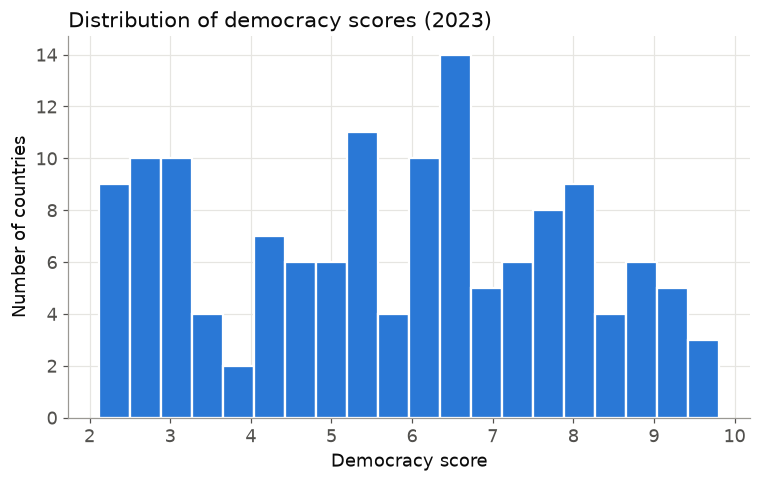

In [12]:
summarize(latest_clean["democracy_eiu"], "democracy score")
print("lowest democracy scores:", latest_clean.sort("democracy_eiu").select("Country", "democracy_eiu").head(5).rows())
print("highest democracy scores:", latest_clean.sort("democracy_eiu", descending=True).select("Country", "democracy_eiu").head(5).rows())

fig, ax = plt.subplots()
ax.hist(latest_clean["democracy_eiu"].to_list(), bins=20, color=BLUE, edgecolor="white", linewidth=1.5)
ax.set_xlabel("Democracy score")
ax.set_ylabel("Number of countries")
ax.set_title("Distribution of democracy scores (2023)", loc="left")
save(fig, "hdi_democracy_distribution")
plt.show()

Democracy scores range from **2.12 to 9.81**, with a middle value of **6.00**. The chart shows countries spread across much of the score range.

### 3.2 HDI and IHDI distribution

HDI: mean=0.735, median=0.758, min=0.394, max=0.967
IHDI: mean=0.603, median=0.627, min=0.261, max=0.910


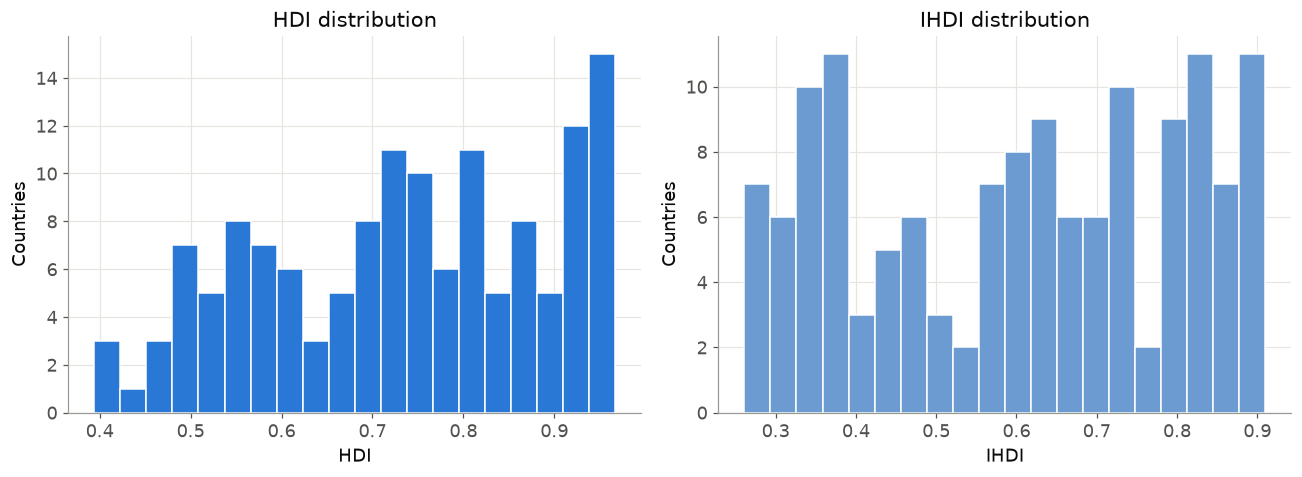

In [13]:
for label, col in [("HDI", "HDI"), ("IHDI", "IHDI")]:
    s = latest_clean[col]
    print(f"{label}: mean={s.mean():.3f}, median={s.median():.3f}, min={s.min():.3f}, max={s.max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(latest_clean["HDI"].to_list(), bins=20, color=BLUE, edgecolor="white")
axes[0].set_title("HDI distribution")
axes[0].set_xlabel("HDI")
axes[0].set_ylabel("Countries")
axes[1].hist(latest_clean["IHDI"].to_list(), bins=20, color="#6b9bd1", edgecolor="white")
axes[1].set_title("IHDI distribution")
axes[1].set_xlabel("IHDI")
axes[1].set_ylabel("Countries")
fig.tight_layout()
save(fig, "hdi_ihdi_distribution")
plt.show()

For these 139 countries, the middle HDI value is **0.758**, while the middle IHDI value is **0.627**. IHDI is lower because it also accounts for inequality.

### 3.3 Inequality loss

inequality loss summary:
inequality loss: n=139  mean=20.177  median=17.647  sd=11.520  IQR=9.535 to 31.204  min=4.752  max=43.003
highest inequality loss: [('Comoros', 43.003412969283275), ('Angola', 41.793570219966156), ('Mozambique', 41.43167028199566), ("Cote d'Ivoire", 40.44943820224719), ('Burkina Faso', 40.410958904109584)]
lowest inequality loss: [('Slovenia', 4.751619870410373), ('Iceland', 5.109489051094885), ('Czechia', 5.251396648044693), ('Slovakia', 5.4970760233918), ('Denmark', 5.672268907563016)]


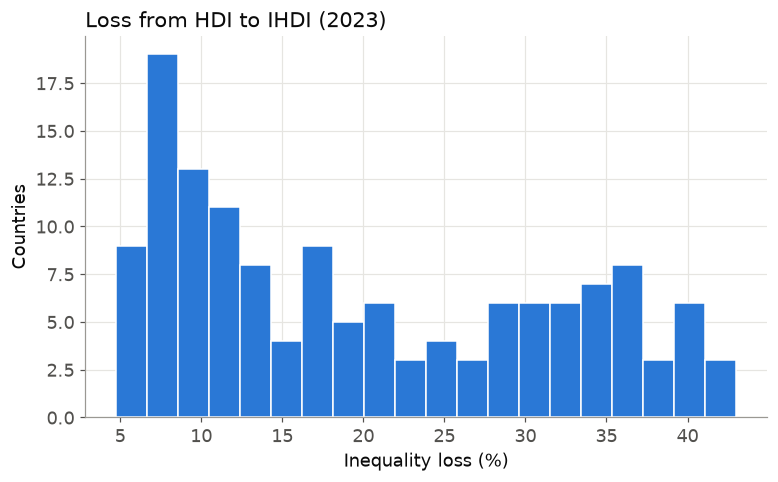

In [14]:
loss = latest_clean.with_columns(
    (100 * (1 - pl.col("IHDI") / pl.col("HDI"))).alias("inequality_loss")
)
print("inequality loss summary:")
summarize(loss["inequality_loss"], "inequality loss")
print("highest inequality loss:", loss.sort("inequality_loss", descending=True).select("Country", "inequality_loss").head(5).rows())
print("lowest inequality loss:", loss.sort("inequality_loss").select("Country", "inequality_loss").head(5).rows())

fig, ax = plt.subplots()
ax.hist(loss["inequality_loss"].to_list(), bins=20, color="#2a78d6", edgecolor="white")
ax.set_xlabel("Inequality loss (%)")
ax.set_ylabel("Countries")
ax.set_title("Loss from HDI to IHDI (2023)", loc="left")

save(fig, "hdi_inequality_loss")
plt.show()

For these countries, the middle loss from HDI to IHDI is about **17.6%**. The loss ranges from about **4.8% to 43.0%**, so the size of the gap differs a lot by country.

## 4. Relationships

This section checks how HDI, IHDI, and democracy are connected in the 2023 data.

### 4.1 Democracy score vs. HDI

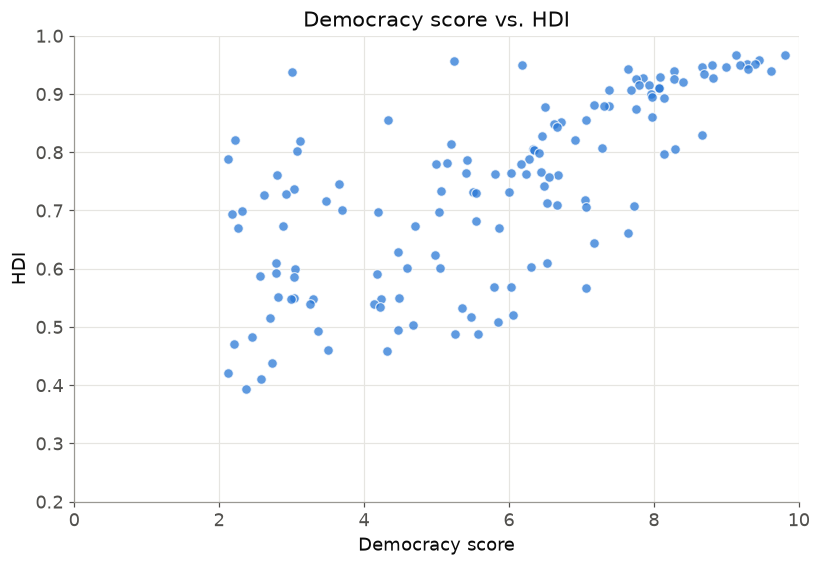

Pearson r between democracy and HDI: 0.697


In [15]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(latest_clean["democracy_eiu"].to_list(), latest_clean["HDI"].to_list(), s=40, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.8)
ax.set_xlabel("Democracy score")
ax.set_ylabel("HDI")
ax.set_title("Democracy score vs. HDI")
ax.set_xlim(0, 10)
ax.set_ylim(0.2, 1.0)
save(fig, "hdi_vs_democracy")
plt.show()

r = latest_clean.select(pl.corr("democracy_eiu", "HDI")).item()
print("Pearson r between democracy and HDI:", round(r, 3))

The chart shows a positive link between democracy scores and HDI. The correlation is **0.697**: countries with higher democracy scores often have higher HDI, but there are exceptions.

### 4.2 Democracy score vs. IHDI

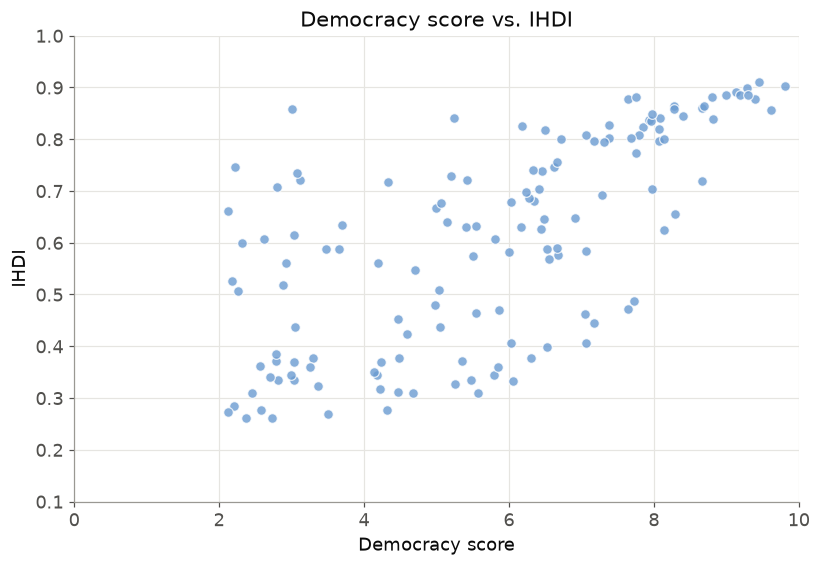

Pearson r between democracy and IHDI: 0.674


In [16]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(latest_clean["democracy_eiu"].to_list(), latest_clean["IHDI"].to_list(), s=40, color="#6b9bd1", alpha=0.8, edgecolor="white", linewidth=0.8)
ax.set_xlabel("Democracy score")
ax.set_ylabel("IHDI")
ax.set_title("Democracy score vs. IHDI")
ax.set_xlim(0, 10)
ax.set_ylim(0.1, 1.0)
save(fig, "ihdi_vs_democracy")
plt.show()

r_ihdi = latest_clean.select(pl.corr("democracy_eiu", "IHDI")).item()
print("Pearson r between democracy and IHDI:", round(r_ihdi, 3))

IHDI also tends to be higher where democracy scores are higher. The correlation is **0.674**, a positive link, though the countries do not all follow the same pattern.

### 4.3 HDI vs. IHDI

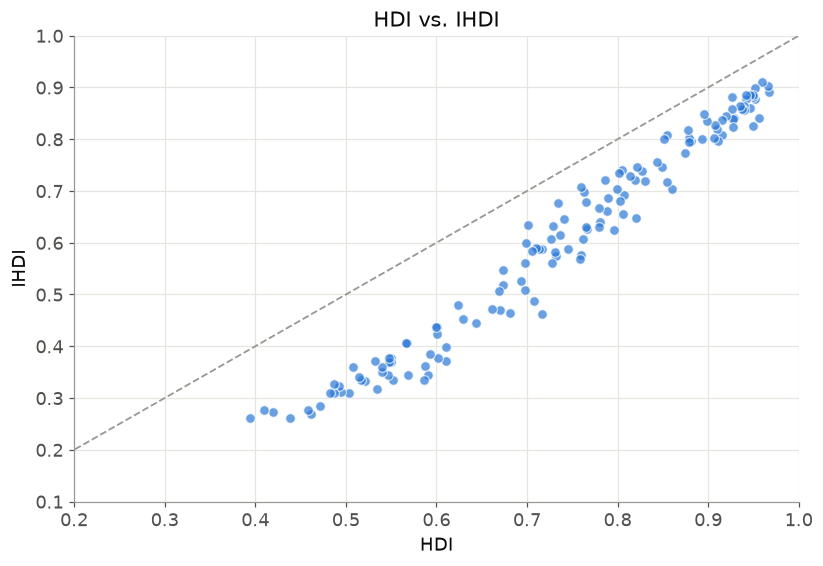

Pearson r between HDI and IHDI: 0.984


In [17]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(latest_clean["HDI"].to_list(), latest_clean["IHDI"].to_list(), s=40, color=BLUE, alpha=0.7, edgecolor="white", linewidth=0.8)
ax.plot([0, 1], [0, 1], linestyle="--", color=GRAY, linewidth=1.2)
ax.set_xlabel("HDI")
ax.set_ylabel("IHDI")
ax.set_title("HDI vs. IHDI")
ax.set_xlim(0.2, 1.0)
ax.set_ylim(0.1, 1.0)
save(fig, "hdi_vs_ihdi")
plt.show()

r_hdi_ihdi = latest_clean.select(pl.corr("HDI", "IHDI")).item()
print("Pearson r between HDI and IHDI:", round(r_hdi_ihdi, 3))

HDI and IHDI move closely together, with a correlation of **0.984**. Most points sit below the diagonal line, which means IHDI is lower than HDI for these countries.

### 4.4 Top countries by gap

In [18]:
with_gap = latest_clean.with_columns(
    (100 * (1 - pl.col("IHDI") / pl.col("HDI"))).alias("inequality_loss")
)
print("largest HDI-IHDI gaps:")
print(with_gap.sort("inequality_loss", descending=True).select("Country", "HDI", "IHDI", "inequality_loss").head(10).rows())

print("smallest HDI-IHDI gaps:")
print(with_gap.sort("inequality_loss").select("Country", "HDI", "IHDI", "inequality_loss").head(10).rows())

largest HDI-IHDI gaps:
[('Comoros', 0.586, 0.334, 43.003412969283275), ('Angola', 0.591, 0.344, 41.793570219966156), ('Mozambique', 0.461, 0.27, 41.43167028199566), ("Cote d'Ivoire", 0.534, 0.318, 40.44943820224719), ('Burkina Faso', 0.438, 0.261, 40.410958904109584), ('Zambia', 0.569, 0.344, 39.54305799648507), ('Sierra Leone', 0.458, 0.277, 39.519650655021834), ('Guinea', 0.471, 0.285, 39.490445859872615), ('Haiti', 0.552, 0.335, 39.31159420289855), ('Eswatini', 0.61, 0.372, 39.016393442622956)]
smallest HDI-IHDI gaps:
[('Slovenia', 0.926, 0.882, 4.751619870410373), ('Iceland', 0.959, 0.91, 5.109489051094885), ('Czechia', 0.895, 0.848, 5.251396648044693), ('Slovakia', 0.855, 0.808, 5.4970760233918), ('Denmark', 0.952, 0.898, 5.672268907563016), ('Finland', 0.942, 0.886, 5.944798301486198), ('Hungary', 0.851, 0.8, 5.992949471210329), ('Netherlands', 0.946, 0.885, 6.448202959830862), ('Norway', 0.966, 0.903, 6.521739130434778), ('Ireland', 0.95, 0.886, 6.736842105263152)]


Comoros has the largest gap in this group, about **43.0%**. Slovenia has the smallest, about **4.8%**. A larger gap means more of the HDI score is lost when inequality is counted.

In the 139 countries with complete data, higher democracy scores tend to appear with higher HDI and IHDI. HDI and IHDI are also closely linked, but IHDI is lower after inequality is counted. The middle loss is about **17.6%**.

These results describe 2023 data. They show links between scores, not proof that one causes another.